# Titulo1

## Titulo2

In [1]:
import pandas as pd

Auditoria e Inspeção de Dados (Inspection Check)

In [2]:
import pandas as pd
from IPython.display import display

# Carregar dados
caminho = "../data_subjects/R_Base Dados_Questionários_Study 2_Guilherme Saldanha.xlsx"
df = pd.read_excel(caminho)

# Configuração de visualização
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 200)

# 1. Estrutura geral
print("=" * 70)
print("INSPEÇÃO INICIAL DO DATASET")
print("=" * 70)

print(f"\nN.º de participantes (linhas): {df.shape[0]}")
print(f"N.º de variáveis (colunas): {df.shape[1]}")

print("\nNomes das variáveis:")
for numero, coluna in enumerate(df.columns, start=1):
    print(f"{numero:02d}. {coluna}")

# 2. Resumo técnico de cada variável
resumo = pd.DataFrame({
    "Variável": df.columns,
    "Tipo de dados": df.dtypes.astype(str).values,
    "N respostas válidas": df.notna().sum().values,
    "N em falta": df.isna().sum().values,
    "N valores únicos": df.nunique(dropna=True).values
})

print("\n" + "=" * 70)
print("RESUMO TÉCNICO DAS VARIÁVEIS")
print("=" * 70)
display(resumo)

# 3. Respostas observadas em cada variável
print("\n" + "=" * 70)
print("RESPOSTAS OBSERVADAS POR VARIÁVEL")
print("=" * 70)

for numero, coluna in enumerate(df.columns, start=1):
    serie = df[coluna]

    print(f"\n{'=' * 70}")
    print(f"{numero:02d}. VARIÁVEL: {coluna}")
    print(f"Tipo: {serie.dtype}")
    print(f"Válidos: {serie.notna().sum()} | Em falta: {serie.isna().sum()} | Únicos: {serie.nunique(dropna=True)}")
    print("-" * 70)

    contagens = (
        serie
        .fillna("[EM FALTA]")
        .astype(str)
        .value_counts(dropna=False)
        .rename_axis("Resposta")
        .reset_index(name="n")
    )

    contagens["%"] = (100 * contagens["n"] / len(df)).round(1)

    display(contagens)

INSPEÇÃO INICIAL DO DATASET

N.º de participantes (linhas): 54
N.º de variáveis (colunas): 45

Nomes das variáveis:
01. ID
02. Data da sessão
03. Mão Dominante
04. Data de nascimento
05. Sexo
06. Nacionalidade
07. Escolaridade
08. Situação/Ocupação Atual
09. É atualmente praticante federado de alguma modalidade desportiva?
10. No caso de ser desportista federado, a sua modalidade principal é:
11. Indique a modalidade principal
12. Escalão Atual em que compete
13. Nível competitivo atual
14. Há quantos anos pratica a modalidade federada atual?
15. Já foi praticante federado anteriormente?
16. A modalidade que praticava era:
17. Indique a modalidade que praticava
18. Durante quanto tempo praticou de forma federada?
19. Há quanto tempo deixou de praticar de forma federada?
20. Último escalão em que competiu
21. Nível competitivo mais elevado que atingiu
22. Pratica atualmente atividade física regular, mesmo sem ser federado?
23. Se sim, qual a atividade/modalidade principal?

24. Se sim, 

,Variável,Tipo de dados,N respostas válidas,N em falta,N valores únicos
0,ID,str,54,0,54
1,Data da sessão,datetime64[us],54,0,31
2,Mão Dominante,str,54,0,2
3,Data de nascimento,datetime64[us],54,0,54
4,Sexo,str,54,0,2
5,Nacionalidade,str,54,0,3
6,Escolaridade,str,54,0,6
7,Situação/Ocupação Atual,str,54,0,3
8,É atualmente praticante federado de alguma modalidade desportiva?,str,54,0,2
9,"No caso de ser desportista federado, a sua modalidade principal é:",str,31,23,2



RESPOSTAS OBSERVADAS POR VARIÁVEL

01. VARIÁVEL: ID
Tipo: str
Válidos: 54 | Em falta: 0 | Únicos: 54
----------------------------------------------------------------------


,Resposta,n,%
0,sub-002,1,1.9
1,sub-003,1,1.9
2,sub-004,1,1.9
3,sub-005,1,1.9
4,sub-006,1,1.9
5,sub-007,1,1.9
6,sub-008,1,1.9
7,sub-009,1,1.9
8,sub-001,1,1.9
9,sub-010,1,1.9



02. VARIÁVEL: Data da sessão
Tipo: datetime64[us]
Válidos: 54 | Em falta: 0 | Únicos: 31
----------------------------------------------------------------------


,Resposta,n,%
0,2026-09-17,4,7.4
1,2026-09-24,4,7.4
2,2026-09-15,3,5.6
3,2026-09-30,3,5.6
4,2026-07-28,2,3.7
5,2026-07-30,2,3.7
6,2026-08-03,2,3.7
7,2026-08-04,2,3.7
8,2026-08-18,2,3.7
9,2026-09-18,2,3.7


... (82 outputs left out)


44. VARIÁVEL: Score IC MIQ-3 
Tipo: int64
Válidos: 54 | Em falta: 0 | Únicos: 15
----------------------------------------------------------------------


,Resposta,n,%
0,22,9,16.7
1,21,8,14.8
2,24,7,13.0
3,25,4,7.4
4,27,4,7.4
5,23,4,7.4
6,28,3,5.6
7,14,3,5.6
8,11,3,5.6
9,16,2,3.7



45. VARIÁVEL: MIQ-3 Total
Tipo: int64
Válidos: 54 | Em falta: 0 | Únicos: 28
----------------------------------------------------------------------


,Resposta,n,%
0,68,5,9.3
1,69,4,7.4
2,60,4,7.4
3,65,3,5.6
4,75,3,5.6
5,71,3,5.6
6,57,3,5.6
7,78,3,5.6
8,84,2,3.7
9,81,2,3.7


Visualização - Caracterização sociodemográfica e desportiva da amostra

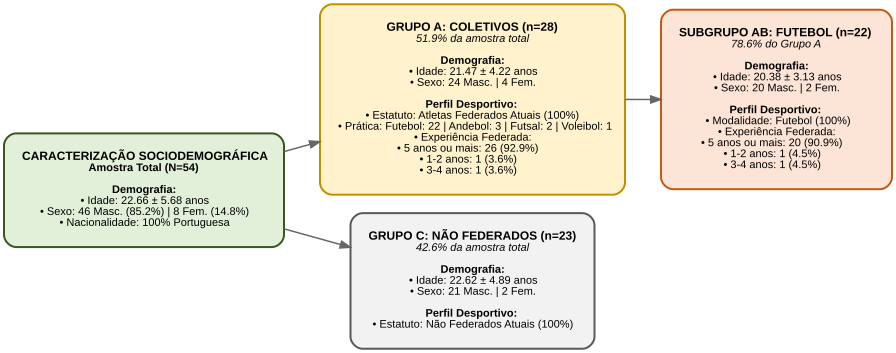

In [ ]:
import pandas as pd
import graphviz
import os
from IPython.display import display

# Forçar o Windows a encontrar o motor Graphviz do Conda
os.environ["PATH"] += os.pathsep + r'C:\Users\guilh\miniconda3\envs\NIRS\Library\bin\graphviz'

caminho = "../data_subjects/R_Base Dados_Questionários_Study 2_Guilherme Saldanha.xlsx"
df = pd.read_excel(caminho)

# Limpeza inicial e formatação
df['Subject'] = df['Código do participante'].astype(str).str.strip()
df['Modalidade'] = df['Indique a modalidade principal'].astype(str).str.strip()
df['Estatuto'] = df['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip()
df['Chronological Age'] = pd.to_numeric(df['Chronological Age'], errors='coerce')

def extrair_experiencia(df_sub):
    col = 'Há quantos anos pratica a modalidade federada atual?'
    if col not in df_sub.columns: return "N/A"
    contagem = df_sub[col].value_counts()
    linhas = [f"{cat}: {val} ({(val/len(df_sub))*100:.1f}%)" for cat, val in contagem.items() if pd.notna(cat) and str(cat).strip() != 'nan']
    return "<br/>&nbsp;&nbsp;&nbsp;• ".join(linhas) if linhas else "Sem dados"

# Cálculos diretos da base de dados sem ajustes artificiais
n_total = len(df)
idade_med_tot, idade_dp_tot = df['Chronological Age'].mean(), df['Chronological Age'].std()
masc_tot = df['Sexo'].str.contains('Masc', case=False, na=False).sum()

modalidades_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol']
df_col = df[(df['Estatuto'] == 'Sim') & (df['Modalidade'].isin(modalidades_coletivas))]
n_col = len(df_col)
idade_med_col, idade_dp_col = df_col['Chronological Age'].mean(), df_col['Chronological Age'].std()
masc_col = df_col['Sexo'].str.contains('Masc', case=False, na=False).sum()
exp_col_txt = extrair_experiencia(df_col)
contagem_mods = df_col['Modalidade'].value_counts()
detalhe_mods = " | ".join([f"{m}: {q}" for m, q in contagem_mods.items()])

df_fut = df_col[df_col['Modalidade'] == 'Futebol']
n_fut = len(df_fut)
idade_med_fut, idade_dp_fut = df_fut['Chronological Age'].mean(), df_fut['Chronological Age'].std()
masc_fut = df_fut['Sexo'].str.contains('Masc', case=False, na=False).sum()
exp_fut_txt = extrair_experiencia(df_fut)

df_nfed = df[df['Estatuto'] == 'Não']
n_nfed = len(df_nfed)
idade_med_nfed, idade_dp_nfed = df_nfed['Chronological Age'].mean(), df_nfed['Chronological Age'].std()
masc_nfed = df_nfed['Sexo'].str.contains('Masc', case=False, na=False).sum()

# Desenhar Diagrama
dot = graphviz.Digraph(comment='Caracterizacao Completa', format='png')
dot.attr(rankdir='LR', size='15,10')
dot.attr('node', shape='box', style='filled,rounded', fontname='Arial', fontsize='11', margin='0.25')

texto_total = f"""<<font point-size="12"><b>CARACTERIZAÇÃO SOCIODEMOGRÁFICA</b></font><br/><b>Amostra Total (N={n_total})</b><br/><br/><b>Demografia:</b><br/>• Idade: {idade_med_tot:.2f} ± {idade_dp_tot:.2f} anos<br/>• Sexo: {masc_tot} Masc. ({(masc_tot/n_total)*100:.1f}%) | {n_total-masc_tot} Fem. ({(1-masc_tot/n_total)*100:.1f}%)<br/>• Nacionalidade: 100% Portuguesa>"""
texto_col = f"""<<font point-size="12"><b>GRUPO A: COLETIVOS (n={n_col})</b></font><br/><i>{ (n_col/n_total)*100:.1f}% da amostra total</i><br/><br/><b>Demografia:</b><br/>• Idade: {idade_med_col:.2f} ± {idade_dp_col:.2f} anos<br/>• Sexo: {masc_col} Masc. | {n_col-masc_col} Fem.<br/><br/><b>Perfil Desportivo:</b><br/>• Estatuto: Atletas Federados Atuais (100%)<br/>• Prática: {detalhe_mods}<br/>• Experiência Federada:<br/>&nbsp;&nbsp;&nbsp;• {exp_col_txt}>"""
texto_fut = f"""<<font point-size="12"><b>SUBGRUPO AB: FUTEBOL (n={n_fut})</b></font><br/><i>{ (n_fut/n_col)*100:.1f}% do Grupo A</i><br/><br/><b>Demografia:</b><br/>• Idade: {idade_med_fut:.2f} ± {idade_dp_fut:.2f} anos<br/>• Sexo: {masc_fut} Masc. | {n_fut-masc_fut} Fem.<br/><br/><b>Perfil Desportivo:</b><br/>• Modalidade: Futebol (100%)<br/>• Experiência Federada:<br/>&nbsp;&nbsp;&nbsp;• {exp_fut_txt}>"""
texto_nfed = f"""<<font point-size="12"><b>GRUPO C: NÃO FEDERADOS (n={n_nfed})</b></font><br/><i>{ (n_nfed/n_total)*100:.1f}% da amostra total</i><br/><br/><b>Demografia:</b><br/>• Idade: {idade_med_nfed:.2f} ± {idade_dp_nfed:.2f} anos<br/>• Sexo: {masc_nfed} Masc. | {n_nfed-masc_nfed} Fem.<br/><br/><b>Perfil Desportivo:</b><br/>• Estatuto: Não Federados Atuais (100%)>"""

dot.node('A', texto_total, fillcolor='#e2f0d9', color='#385723', penwidth='2')
dot.node('B', texto_col, fillcolor='#fff2cc', color='#bf9000', penwidth='2')
dot.node('C', texto_fut, fillcolor='#fce4d6', color='#c65911', penwidth='2')
dot.node('D', texto_nfed, fillcolor='#f2f2f2', color='#595959', penwidth='2')

dot.edge('A', 'B', color='gray40', penwidth='1.5')
dot.edge('B', 'C', color='gray40', penwidth='1.5')
dot.edge('A', 'D', color='gray40', penwidth='1.5')

display(dot)

DESCRITIVOS GRUPO C - NÃO FEDERADOS

In [3]:
from pathlib import Path
import pandas as pd

# Localizar a raiz do repositório a partir da pasta atual
pasta_atual = Path.cwd().resolve()

raiz = next(
    (
        pasta
        for pasta in [pasta_atual, *pasta_atual.parents]
        if (pasta / "data_subjects" / "Merge_Dataset_Study_2.xlsx").is_file()
    ),
    None
)

if raiz is None:
    raise FileNotFoundError(
        "Não foi encontrado data_subjects/Merge_Dataset_Study_2.xlsx "
        f"a partir da pasta atual: {pasta_atual}"
    )

caminho_base = raiz / "data_subjects" / "Merge_Dataset_Study_2.xlsx"

df = pd.read_excel(
    caminho_base,
    sheet_name="Merge Dataset",
    engine="openpyxl"
)

print(f"Base carregada: {caminho_base}")
print(f"Participantes: {len(df)}")
print(f"Colunas: {len(df.columns)}")

Base carregada: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Merge_Dataset_Study_2.xlsx
Participantes: 54
Colunas: 78


In [4]:
# ==========================================================
# DESCRITIVOS DO GRUPO C — HISTÓRICO DESPORTIVO
# Usa df em memória; não altera df nem apaga resultados.
# ==========================================================

from pathlib import Path
import unicodedata
import re
import pandas as pd
from IPython.display import display

PASTA = Path("../data_subjects/Descritivos_Grupo_C")
PASTA.mkdir(parents=True, exist_ok=True)

COL = {
    "id": "ID",
    "sexo": "Sexo",
    "atual": "É atualmente praticante federado de alguma modalidade desportiva?",
    "anterior": "Já foi praticante federado anteriormente?",
    "tipo": "A modalidade que praticava era:",
    "modalidade": "Indique a modalidade que praticava",
    "duracao": "Durante quanto tempo praticou de forma federada?",
    "cessacao": "Há quanto tempo deixou de praticar de forma federada?"
}


def normalizar(valor):
    if pd.isna(valor):
        return ""
    texto = unicodedata.normalize("NFD", str(valor))
    texto = "".join(
        c for c in texto if unicodedata.category(c) != "Mn"
    )
    texto = texto.replace("\xa0", " ").replace("–", "-").replace("—", "-")
    return " ".join(texto.lower().strip().split())


def percentagem(n, denominador):
    return 100 * n / denominador if denominador else float("nan")


def pct_texto(n, denominador):
    return f"{percentagem(n, denominador):.1f}"


# 1. Validar a base
if "df" not in globals() or not isinstance(df, pd.DataFrame):
    raise ValueError("Carrega primeiro o dataframe df.")

base = df.copy()
base.columns = [
    " ".join(str(c).replace("\xa0", " ").strip().split())
    for c in base.columns
]

if base.columns.duplicated().any():
    raise ValueError("Existem nomes de colunas duplicados.")

faltam = [c for c in COL.values() if c not in base.columns]
if faltam:
    raise KeyError("Colunas em falta:\n- " + "\n- ".join(faltam))

if base[COL["id"]].isna().any():
    raise ValueError("Existem IDs omissos.")

base[COL["id"]] = base[COL["id"]].astype(str).str.strip()

if (
    base[COL["id"]].eq("").any()
    or base[COL["id"]].duplicated().any()
):
    raise ValueError("Existem IDs vazios ou duplicados.")

# 2. Selecionar Grupo C
grupo_c = base.loc[
    base[COL["atual"]].map(normalizar).eq("nao"),
    list(COL.values())
].copy()

if grupo_c.empty:
    raise ValueError("Não foram encontrados participantes do Grupo C.")

for chave in ["sexo", "anterior", "tipo", "modalidade", "duracao", "cessacao"]:
    grupo_c[f"_{chave}"] = grupo_c[COL[chave]].map(normalizar)

antigos = grupo_c.loc[grupo_c["_anterior"].eq("sim")].copy()

n_c = len(grupo_c)
n_antigos = len(antigos)

# 3. Classificações explícitas
mapa_tipo = {
    "modalidade coletiva": "Team sports",
    "modalidade individual": "Individual sports"
}

mapa_duracao = {
    "menos de 1 ano": "<1 year",
    "1-2 anos": "1–2 years",
    "3-4 anos": "3–4 years",
    "5 anos ou mais": "≥5 years"
}

mapa_cessacao = {
    "menos de 1 ano": "<1 year",
    "1-3 anos": "1–3 years",
    "4-6 anos": "4–6 years",
    "7-9 anos": "7–9 years",
    "10 anos ou mais": "≥10 years",
    "mais de 10 anos": ">10 years"
}

antigos["Categoria declarada"] = antigos["_tipo"].map(mapa_tipo)
antigos["Duração classificada"] = antigos["_duracao"].map(mapa_duracao)
antigos["Cessação classificada"] = antigos["_cessacao"].map(mapa_cessacao)

# Palavra "futebol", incluindo listas de modalidades.
# Não inclui "futsal" nem termos não declarados como futebol.
antigos["Futebol mencionado"] = antigos["_modalidade"].str.contains(
    r"\bfutebol\b", regex=True, na=False
)

# "Mais de 10 anos" também satisfaz o limiar ≥10.
antigos.loc[
    antigos["Cessação classificada"].eq(">10 years"),
    "Cessação classificada"
] = "≥10 years"

# 4. Auditoria: não ignorar omissões ou categorias desconhecidas
problemas = []


def registar_problema(linhas, campo, motivo):
    for _, linha in linhas.iterrows():
        problemas.append({
            "ID": linha[COL["id"]],
            "Campo": COL[campo],
            "Resposta original": linha[COL[campo]],
            "Problema": motivo
        })


registar_problema(
    grupo_c.loc[~grupo_c["_sexo"].isin(["masculino", "feminino"])],
    "sexo", "Resposta omissa ou não contemplada pelo texto do manuscrito"
)

registar_problema(
    grupo_c.loc[~grupo_c["_anterior"].isin(["sim", "nao"])],
    "anterior", "Resposta omissa ou desconhecida"
)

for campo, derivada in [
    ("tipo", "Categoria declarada"),
    ("duracao", "Duração classificada"),
    ("cessacao", "Cessação classificada")
]:
    registar_problema(
        antigos.loc[antigos[derivada].isna()],
        campo, "Resposta omissa ou categoria não reconhecida"
    )

registar_problema(
    antigos.loc[antigos["_modalidade"].eq("")],
    "modalidade", "Modalidade anterior omissa"
)

if n_antigos == 0:
    problemas.append({
        "ID": "",
        "Campo": COL["anterior"],
        "Resposta original": "",
        "Problema": "Nenhum antigo federado: percentagens condicionais indefinidas"
    })

auditoria = pd.DataFrame(
    problemas,
    columns=["ID", "Campo", "Resposta original", "Problema"]
)

# 5. Tabela de resultados e denominadores
linhas_resumo = []


def adicionar(indicador, n, denominador, universo):
    linhas_resumo.append({
        "Indicador": indicador,
        "n": int(n),
        "Denominador": int(denominador),
        "Percentagem": percentagem(n, denominador),
        "Universo": universo
    })


n_m = grupo_c["_sexo"].eq("masculino").sum()
n_f = grupo_c["_sexo"].eq("feminino").sum()
n_coletivos = antigos["Categoria declarada"].eq("Team sports").sum()
n_individuais = antigos["Categoria declarada"].eq("Individual sports").sum()
n_5anos = antigos["Duração classificada"].eq("≥5 years").sum()
n_futebol = antigos["Futebol mencionado"].sum()

adicionar("Male", n_m, n_c, "Group C")
adicionar("Female", n_f, n_c, "Group C")
adicionar("Previous federated participation", n_antigos, n_c, "Group C")
adicionar("Previous team sports — declared category", n_coletivos, n_antigos,
          "Former federated athletes in Group C")
adicionar("Previous individual sports — declared category", n_individuais,
          n_antigos, "Former federated athletes in Group C")
adicionar("Federated participation ≥5 years", n_5anos, n_antigos,
          "Former federated athletes in Group C")
adicionar("Previous federated football experience", n_futebol, n_c, "Group C")

ordem_cessacao = ["<1 year", "1–3 years", "4–6 years", "7–9 years", "≥10 years"]

contagens_cessacao = (
    antigos["Cessação classificada"]
    .value_counts()
    .reindex(ordem_cessacao, fill_value=0)
)

for categoria, n in contagens_cessacao.items():
    adicionar(
        f"Time since cessation: {categoria}", n, n_antigos,
        "Former federated athletes in Group C"
    )

resumo = pd.DataFrame(linhas_resumo)

# 6. Dados por participante para conferência
conferencia = grupo_c.merge(
    antigos[[
        COL["id"], "Categoria declarada", "Duração classificada",
        "Cessação classificada", "Futebol mencionado"
    ]],
    on=COL["id"], how="left", validate="one_to_one"
)

conferencia = conferencia.drop(
    columns=[c for c in conferencia.columns if c.startswith("_")]
)

# Conferir listas com múltiplas modalidades ou categoria individual + futebol
rever_modalidades = antigos.loc[
    antigos["_modalidade"].str.contains(r"[,;/]|\be\b", regex=True)
    | (
        antigos["Categoria declarada"].eq("Individual sports")
        & antigos["Futebol mencionado"]
    ),
    [COL["id"], COL["tipo"], COL["modalidade"], "Futebol mencionado"]
].copy()

# 7. Gerar parágrafo apenas quando não há omissões/desconhecidos
if auditoria.empty:
    p = {
        categoria: pct_texto(int(n), n_antigos)
        for categoria, n in contagens_cessacao.items()
    }

    paragrafo = (
        f"Group C included {n_m} male and {n_f} female participants. "
        f"Although they were not currently involved in federated sport, "
        f"{pct_texto(n_antigos, n_c)}% (n = {n_antigos}) reported previous "
        f"federated sport participation, including {n_coletivos} participants "
        f"who classified their previous sport as a team sport and "
        f"{n_individuais} who classified it as an individual sport. "
        f"Among former federated athletes, {pct_texto(n_5anos, n_antigos)}% "
        f"had participated for at least five years. "
        f"Time since cessation of federated sport participation was less "
        f"than one year for {p['<1 year']}%, "
        f"1–3 years for {p['1–3 years']}%, "
        f"4–6 years for {p['4–6 years']}%, "
        f"7–9 years for {p['7–9 years']}%, and "
        f"10 years or more for {p['≥10 years']}%. "
        f"Within Group C, {n_futebol} participants reported previous "
        f"federated football experience."
    )
else:
    paragrafo = (
        "PARÁGRAFO NÃO GERADO: verificar a folha Auditoria. "
        "As percentagens da tabela mantêm os denominadores completos; "
        "não excluem silenciosamente respostas omissas ou desconhecidas."
    )

# 8. Exportação
ficheiro = PASTA / "Descritivos_Grupo_C_Historico.xlsx"

with pd.ExcelWriter(ficheiro, engine="openpyxl") as writer:
    resumo.to_excel(writer, sheet_name="Resumo", index=False)
    conferencia.to_excel(writer, sheet_name="Conferencia_ID", index=False)
    auditoria.to_excel(writer, sheet_name="Auditoria", index=False)
    rever_modalidades.to_excel(
        writer, sheet_name="Rever_modalidades", index=False
    )
    pd.DataFrame({"Texto": [paragrafo]}).to_excel(
        writer, sheet_name="Manuscrito", index=False
    )

    for ws in writer.sheets.values():
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

resumo.to_csv(
    PASTA / "Resumo_Grupo_C.csv",
    index=False, encoding="utf-8-sig"
)

(PASTA / "Paragrafo_Grupo_C.txt").write_text(
    paragrafo, encoding="utf-8"
)

print(f"Grupo C: {n_c} participantes")
print(f"Antigos federados: {n_antigos}")
print(f"Problemas de preenchimento/classificação: {len(auditoria)}")
print(f"Respostas de modalidades para revisão: {len(rever_modalidades)}")
print(f"\nExcel: {ficheiro.resolve()}")
print("\n" + paragrafo)

display(resumo.round({"Percentagem": 1}))

if not auditoria.empty:
    display(auditoria)

if not rever_modalidades.empty:
    display(rever_modalidades)

Grupo C: 23 participantes
Antigos federados: 20
Problemas de preenchimento/classificação: 0
Respostas de modalidades para revisão: 1

Excel: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Descritivos_Grupo_C\Descritivos_Grupo_C_Historico.xlsx

Group C included 21 male and 2 female participants. Although they were not currently involved in federated sport, 87.0% (n = 20) reported previous federated sport participation, including 18 participants who classified their previous sport as a team sport and 2 who classified it as an individual sport. Among former federated athletes, 65.0% had participated for at least five years. Time since cessation of federated sport participation was less than one year for 15.0%, 1–3 years for 30.0%, 4–6 years for 45.0%, 7–9 years for 10.0%, and 10 years or more for 0.0%. Within Group C, 14 participants reported previous federated football experience.


,Indicador,n,Denominador,Percentagem,Universo
0,Male,21,23,91.3,Group C
1,Female,2,23,8.7,Group C
2,Previous federated participation,20,23,87.0,Group C
3,Previous team sports — declared category,18,20,90.0,Former federated athletes in Group C
4,Previous individual sports — declared category,2,20,10.0,Former federated athletes in Group C
5,Federated participation ≥5 years,13,20,65.0,Former federated athletes in Group C
6,Previous federated football experience,14,23,60.9,Group C
7,Time since cessation: <1 year,3,20,15.0,Former federated athletes in Group C
8,Time since cessation: 1–3 years,6,20,30.0,Former federated athletes in Group C
9,Time since cessation: 4–6 years,9,20,45.0,Former federated athletes in Group C


,ID,A modalidade que praticava era:,Indique a modalidade que praticava,Futebol mencionado
26,sub-027,Modalidade Individual,"Karaté , Futebol e Ténis",True


Boxplots Idades por Grupos

Participantes carregados: 54
Idades válidas: 54
Idades omissas/inválidas: 0
VERIFICAÇÃO DAS CONTAGENS
Grupo A — Coletivos: 28
Subgrupo AB — Futebol: 22
Grupo C — Não federados: 23
Outros federados — Individuais: 3
Linhas no dataframe exclusivo do gráfico: 76


C:\Users\guilh\AppData\Local\Temp\ipykernel_3832\1740682718.py:138: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


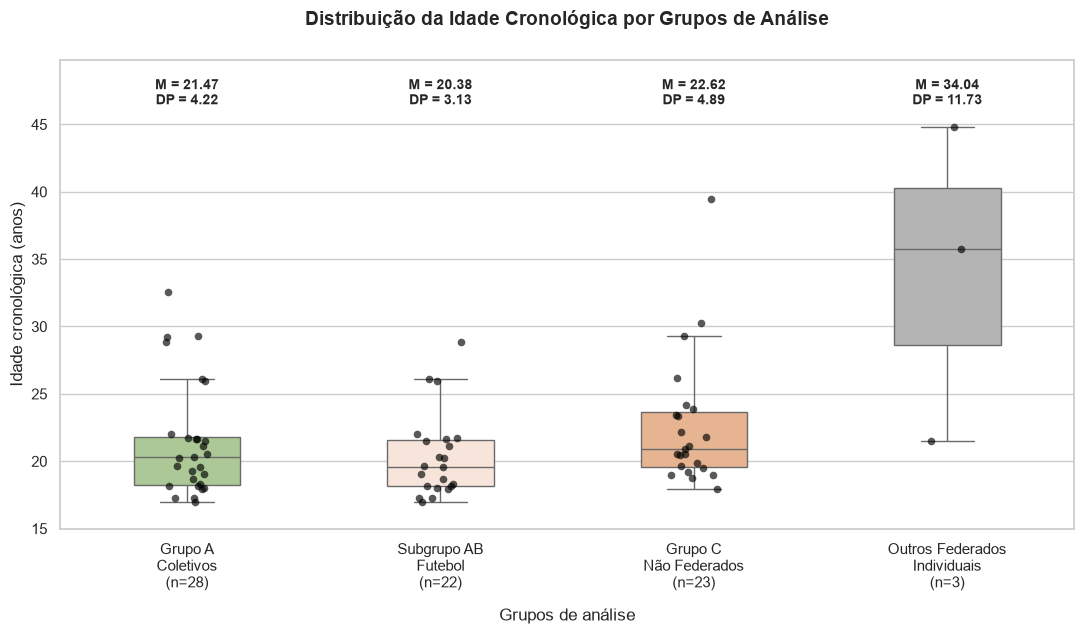

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar a base de dados
caminho = (
    "../data_subjects/"
    "R_Base Dados_Questionários_Study 2_Guilherme Saldanha.xlsx"
)

df = pd.read_excel(caminho)

# Limpar espaços nos nomes das colunas, incluindo espaços invisíveis
df.columns = (
    df.columns.astype(str)
    .str.replace("\xa0", " ", regex=False)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Verificar apenas as colunas necessárias ao gráfico
col_estatuto = (
    "É atualmente praticante federado de alguma modalidade desportiva?"
)

necessarias = [
    "Indique a modalidade principal",
    col_estatuto,
    "Chronological Age"
]

faltam = [col for col in necessarias if col not in df.columns]

if faltam:
    print("Colunas disponíveis no ficheiro:")
    for coluna in df.columns:
        print(repr(coluna))

    raise KeyError(f"Colunas necessárias não encontradas: {faltam}")

# 2. Preparar variáveis para a classificação
df["Modalidade"] = (
    df["Indique a modalidade principal"]
    .astype("string")
    .str.replace("\xa0", " ", regex=False)
    .str.strip()
    .str.title()
)

df["Estatuto"] = (
    df[col_estatuto]
    .astype("string")
    .str.strip()
    .str.capitalize()
)

df["Chronological Age"] = pd.to_numeric(
    df["Chronological Age"]
    .astype("string")
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

modalidades_coletivas = ["Futebol", "Futsal", "Andebol", "Voleibol"]

print(f"Participantes carregados: {len(df)}")
print(f"Idades válidas: {df['Chronological Age'].notna().sum()}")
print(f"Idades omissas/inválidas: {df['Chronological Age'].isna().sum()}")

# 3. Criar dataframes independentes para a figura
df_A = df.loc[
    (df["Estatuto"] == "Sim")
    & (df["Modalidade"].isin(modalidades_coletivas))
].copy()

df_A["Grupo_Analise"] = "Grupo A\nColetivos"

df_AB = df_A.loc[
    df_A["Modalidade"] == "Futebol"
].copy()

df_AB["Grupo_Analise"] = "Subgrupo AB\nFutebol"

df_C = df.loc[
    df["Estatuto"] == "Não"
].copy()

df_C["Grupo_Analise"] = "Grupo C\nNão Federados"

df_D = df.loc[
    (df["Estatuto"] == "Sim")
    & (~df["Modalidade"].isin(modalidades_coletivas))
].copy()

df_D["Grupo_Analise"] = "Outros Federados\nIndividuais"

# 4. Construir labels a partir das contagens reais
labels_grupos = {
    "A": f"Grupo A\nColetivos\n(n={len(df_A)})",
    "AB": f"Subgrupo AB\nFutebol\n(n={len(df_AB)})",
    "C": f"Grupo C\nNão Federados\n(n={len(df_C)})",
    "D": f"Outros Federados\nIndividuais\n(n={len(df_D)})"
}

df_A["Grupo_Analise"] = labels_grupos["A"]
df_AB["Grupo_Analise"] = labels_grupos["AB"]
df_C["Grupo_Analise"] = labels_grupos["C"]
df_D["Grupo_Analise"] = labels_grupos["D"]

# Junta cópias para fins exclusivamente visuais.
# Os atletas de Futebol surgem em A e, simultaneamente, em AB.
df_grafico = pd.concat(
    [df_A, df_AB, df_C, df_D],
    ignore_index=True
)

ordem_grupos = [
    labels_grupos["A"],
    labels_grupos["AB"],
    labels_grupos["C"],
    labels_grupos["D"]
]

# 5. Verificação antes do gráfico
print("VERIFICAÇÃO DAS CONTAGENS")
print(f"Grupo A — Coletivos: {len(df_A)}")
print(f"Subgrupo AB — Futebol: {len(df_AB)}")
print(f"Grupo C — Não federados: {len(df_C)}")
print(f"Outros federados — Individuais: {len(df_D)}")
print(f"Linhas no dataframe exclusivo do gráfico: {len(df_grafico)}")

# 6. Construir a figura
sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(11, 6.5))

sns.boxplot(
    data=df_grafico,
    x="Grupo_Analise",
    y="Chronological Age",
    order=ordem_grupos,
    palette=["#A9D08E", "#FCE4D6", "#F4B183", "#B4B4B4"],
    width=0.42,
    fliersize=0,
    ax=ax
)

sns.stripplot(
    data=df_grafico,
    x="Grupo_Analise",
    y="Chronological Age",
    order=ordem_grupos,
    color="black",
    alpha=0.65,
    size=5.5,
    jitter=0.10,
    ax=ax
)

# 7. Inserir média e desvio-padrão
max_idade = df_grafico["Chronological Age"].max()
posicao_texto = max_idade + 1.4

for i, grupo in enumerate(ordem_grupos):
    idades = df_grafico.loc[
        df_grafico["Grupo_Analise"] == grupo,
        "Chronological Age"
    ]

    media = idades.mean()
    dp = idades.std()

    ax.text(
        i,
        posicao_texto,
        f"M = {media:.2f}\nDP = {dp:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# 8. Formatação
ax.set_title(
    "Distribuição da Idade Cronológica por Grupos de Análise",
    fontsize=14,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Grupos de análise", fontsize=12, labelpad=12)
ax.set_ylabel("Idade cronológica (anos)", fontsize=12)

ax.set_ylim(15, max_idade + 5)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

Verificação Variaveis Merge Dataset

In [7]:
from pathlib import Path
import pandas as pd

pasta_dados = Path("../data_subjects")
ficheiro_merge = pasta_dados / "Merge_Dataset_Study_2.xlsx"

df = pd.read_excel(ficheiro_merge, sheet_name=0)

levantamento = pd.DataFrame({
    "Variavel": df.columns,
    "Tipo_de_dado": df.dtypes.astype(str).values,
    "N_validos": df.notna().sum().values,
    "N_missing": df.isna().sum().values,
    "Percentagem_missing": (df.isna().mean() * 100).round(2).values,
    "N_valores_unicos": df.nunique(dropna=True).values,
    "Exemplo": [
        " | ".join(df[col].dropna().astype(str).unique()[:3])
        for col in df.columns
    ]
})

display(levantamento)

levantamento.to_excel(
    pasta_dados / "Dicionario_Variaveis_Merge.xlsx",
    sheet_name="Dicionario",
    index=False
)

,Variavel,Tipo_de_dado,N_validos,N_missing,Percentagem_missing,N_valores_unicos,Exemplo
0,ID,str,54,0,0.0,54,sub-001 | sub-002 | sub-003
1,Data da sessão,datetime64[us],54,0,0.0,31,2026-08-04 | 2026-07-28 | 2026-07-29
2,Mão Dominante,str,54,0,0.0,2,Direita | Esquerda
3,Data de nascimento,datetime64[us],54,0,0.0,54,2003-03-03 | 1996-04-17 | 2000-08-26
4,Sexo,str,54,0,0.0,2,Feminino | Masculino
...,...,...,...,...,...,...,...
73,ST_Acc_N_Total,int64,54,0,0.0,22,107 | 114 | 100
74,ST_RT_Medio_Total_seg,float64,54,0,0.0,54,1.195577877441216 | 1.013061973214779 | 1.1265...
75,ST_R2_RT_Min_seg,float64,54,0,0.0,54,0.744377100141719 | 0.6559488999191672 | 0.623...
76,ST_R2_RT_Max_seg,float64,54,0,0.0,54,1.686846500029787 | 1.556367299985141 | 1.6561...


BOXPLOTS - Visualização Desempenho Comportamental por Grupos

Número total de participantes: 54

Valores de estatuto encontrados:
['nao', 'sim']

Modalidades encontradas:
['', 'andebol', 'atletismo', 'atletismo e patinagem artistica', 'futebol', 'futsal', 'voleibol']

VERIFICAÇÃO DAS CONTAGENS
Grupo A — Federados, modalidades coletivas: 28
Subgrupo AB — Futebol: 22
Grupo C — Não Federados: 23
Grupo D — Federados, modalidades individuais: 3
Linhas no dataframe destinado aos gráficos: 76


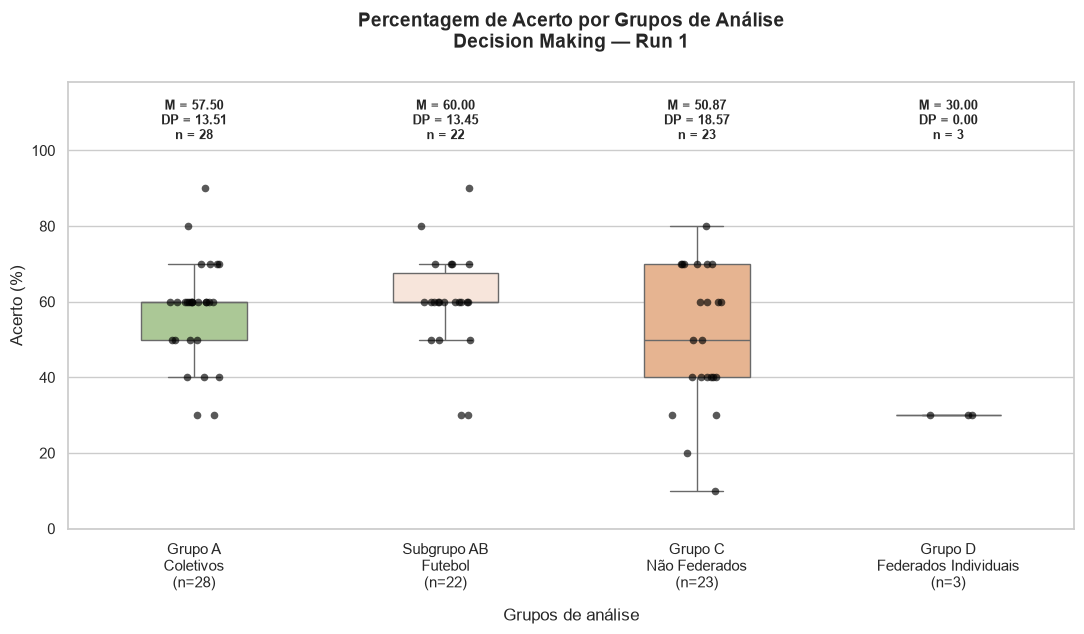

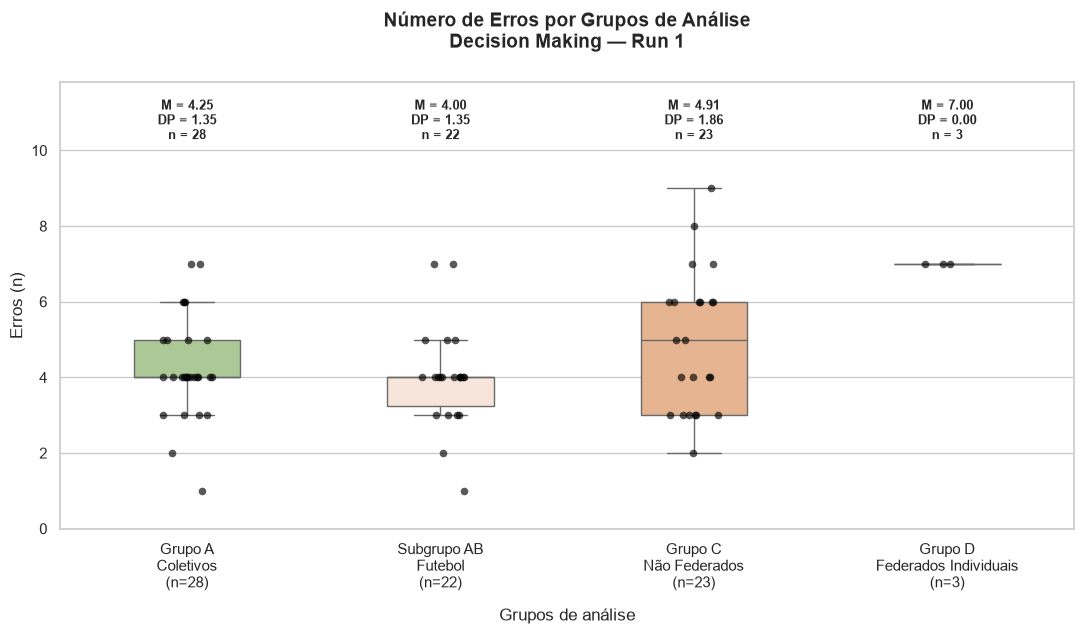

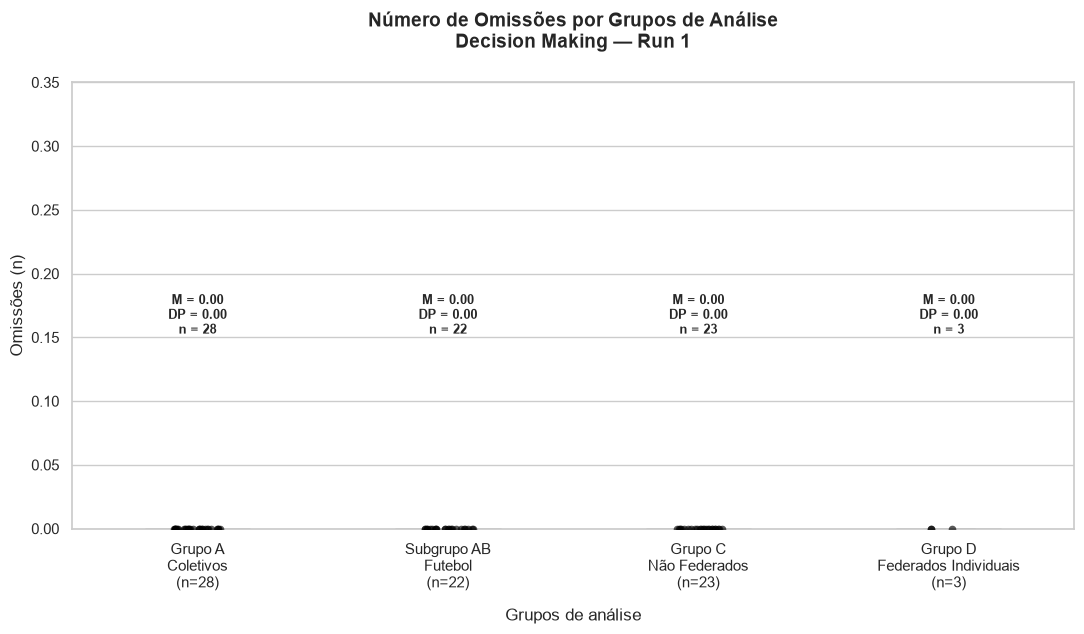

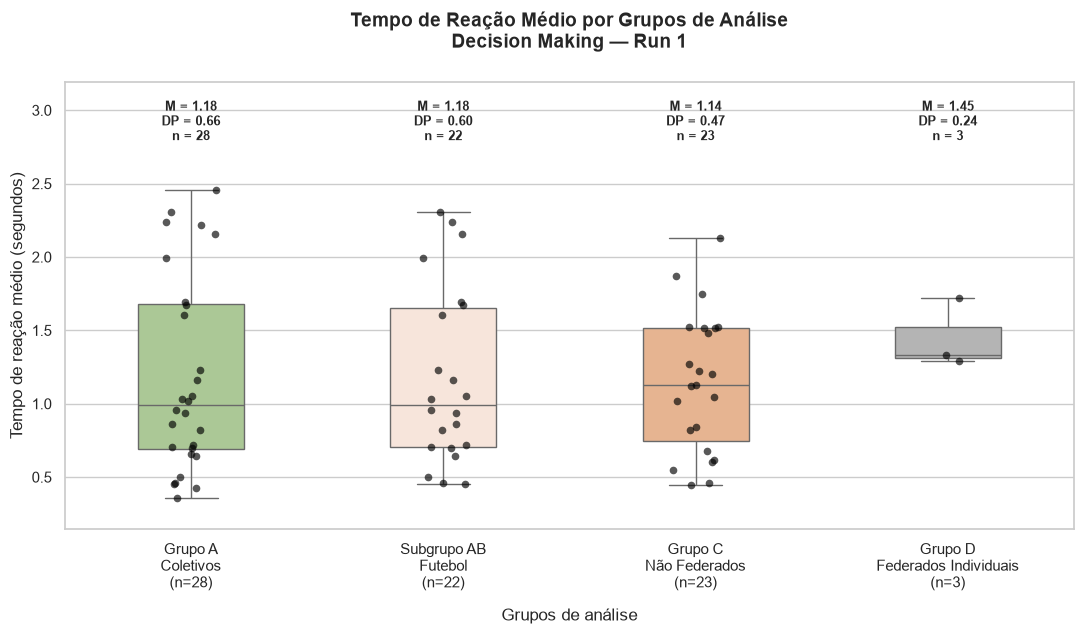

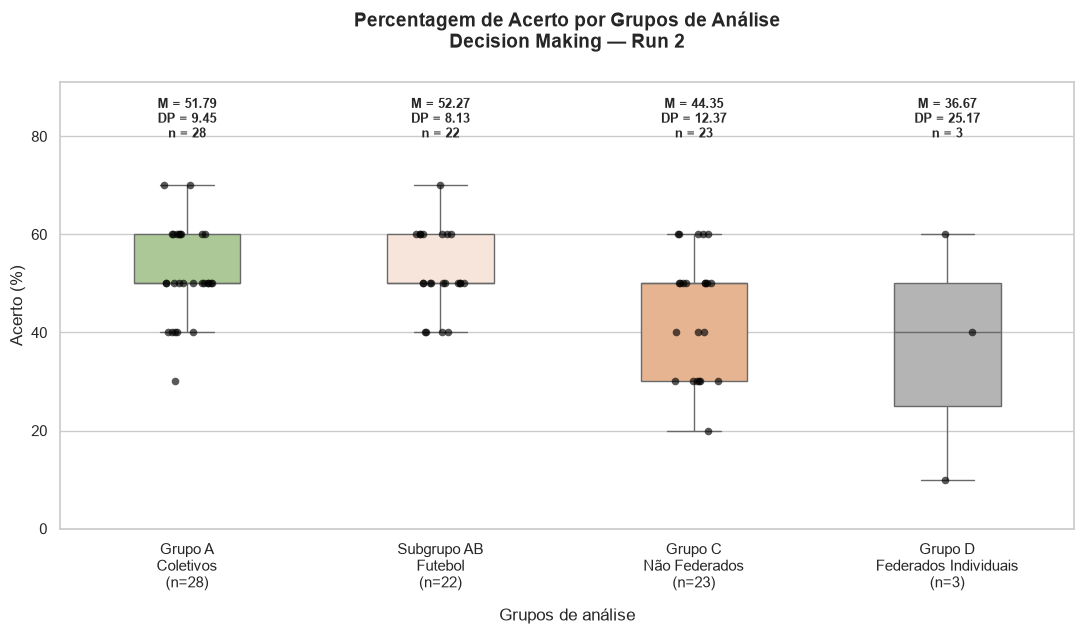

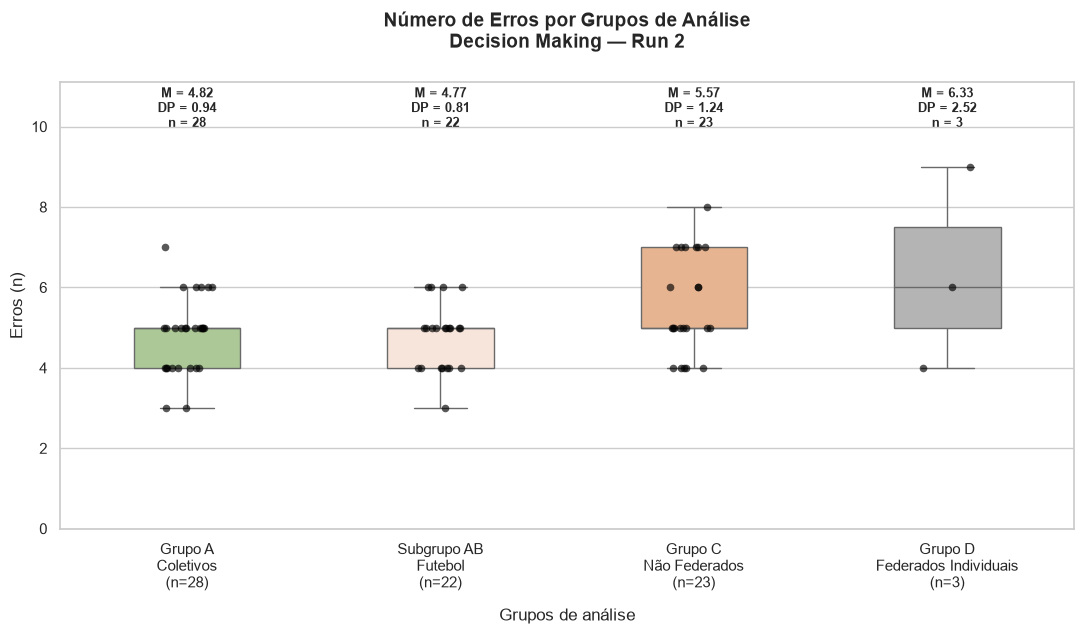

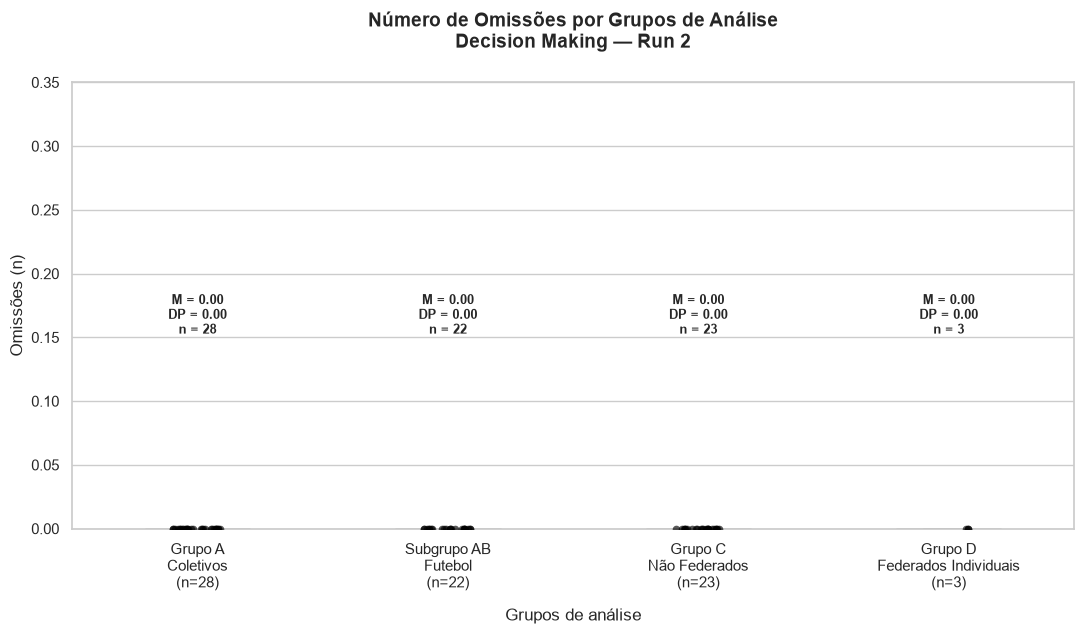

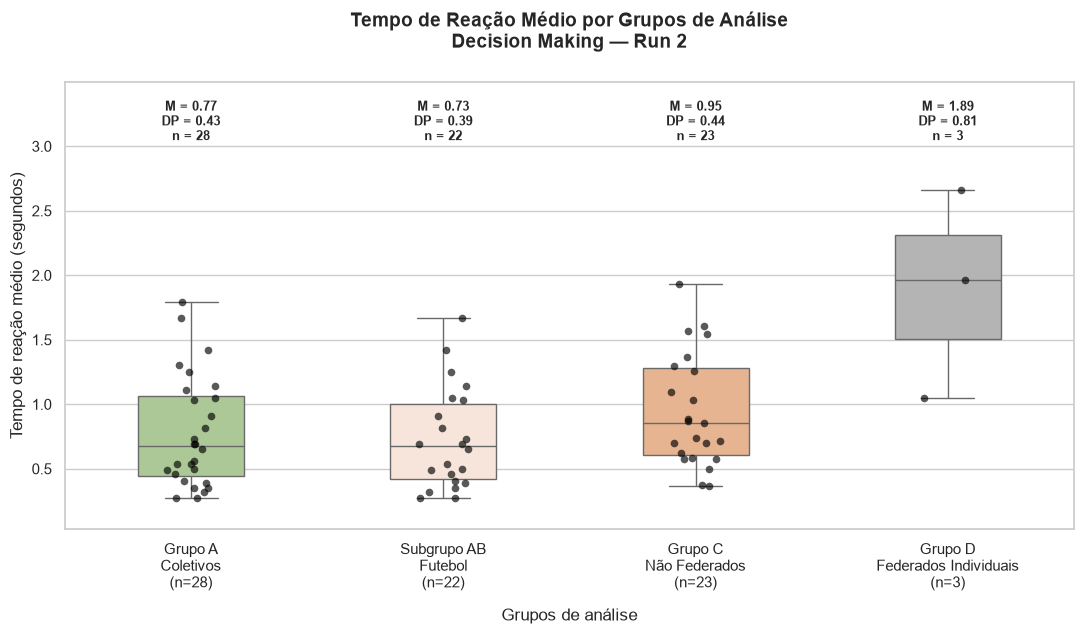

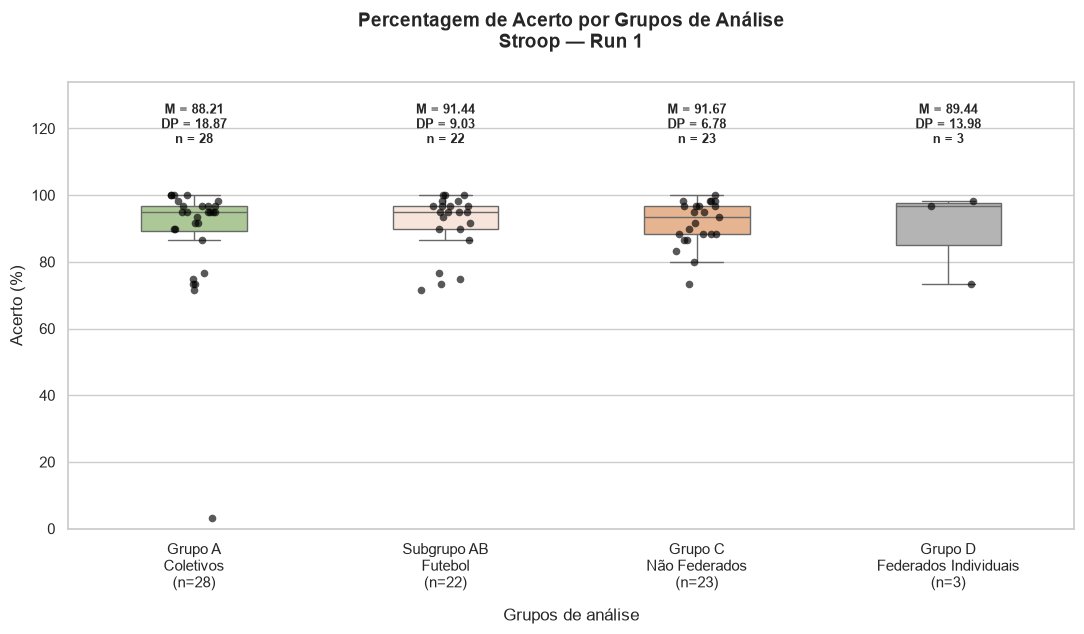

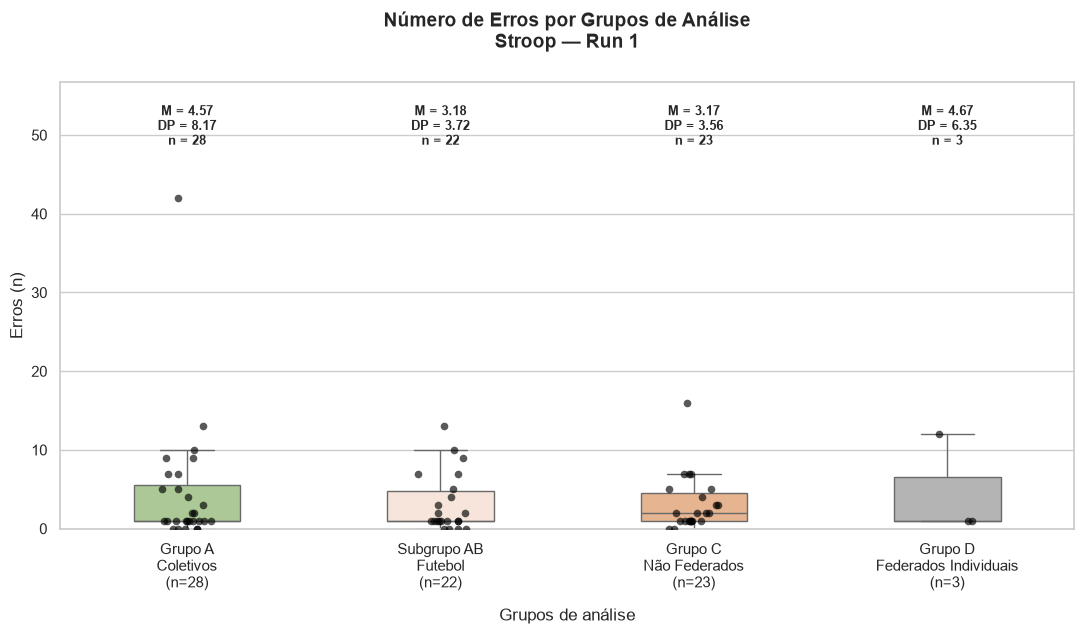

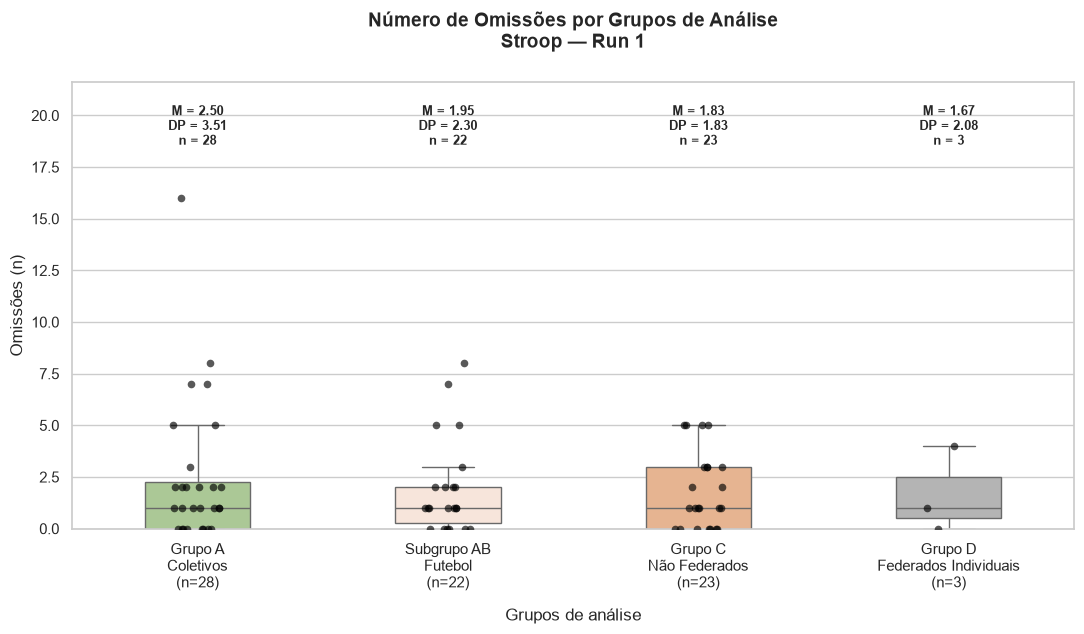

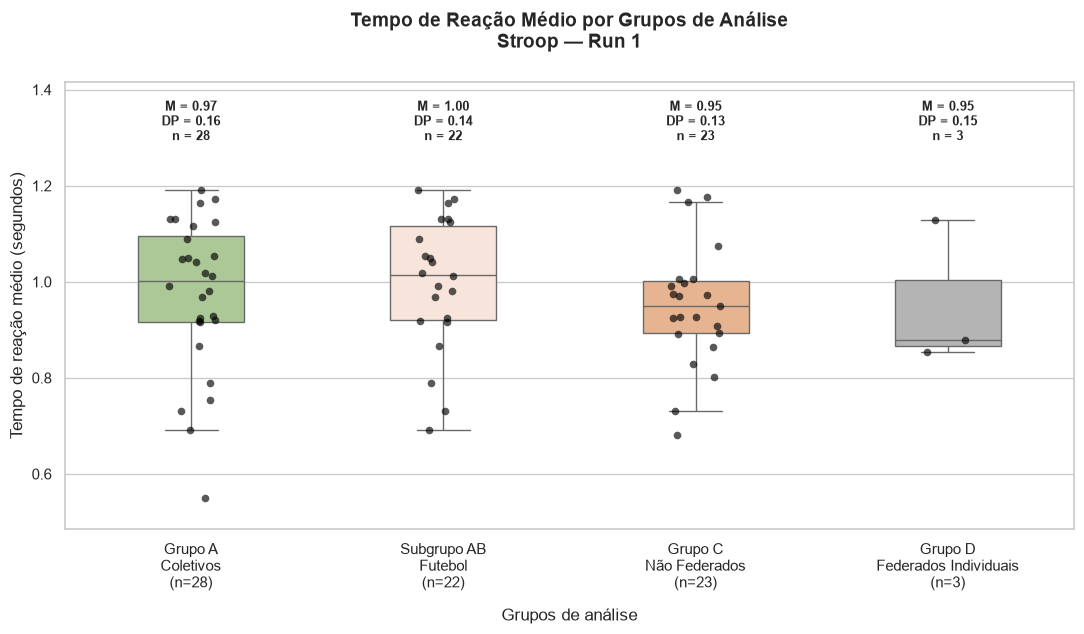

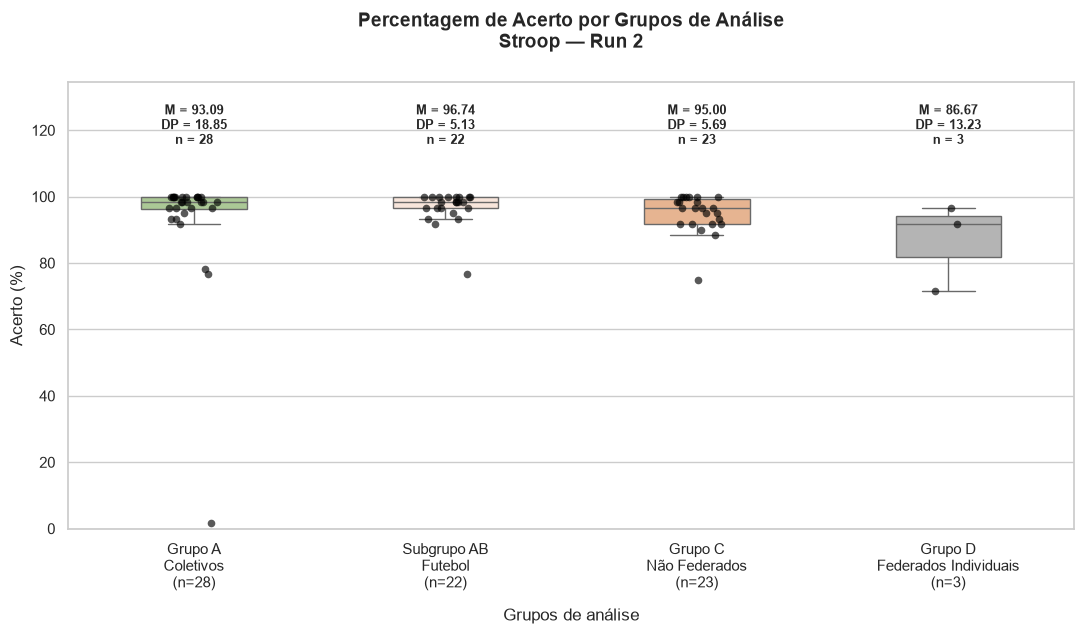

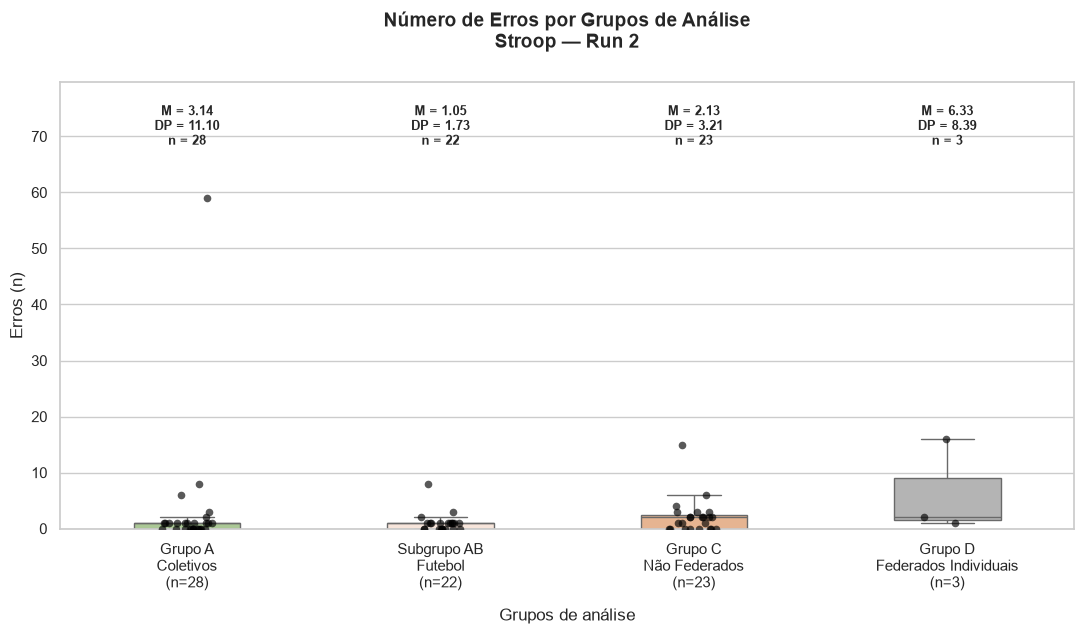

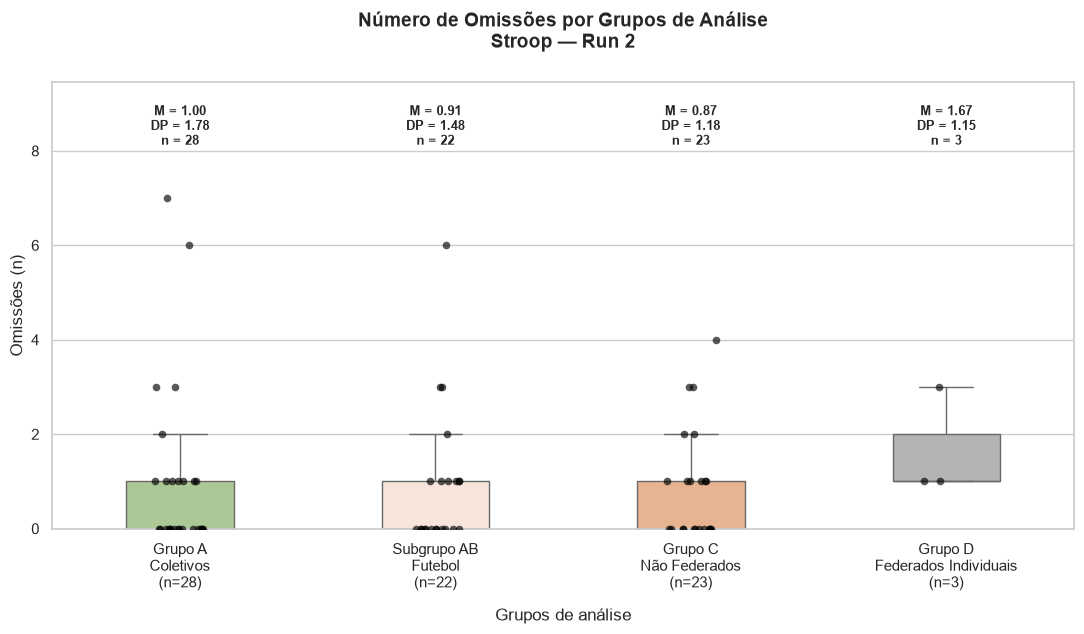

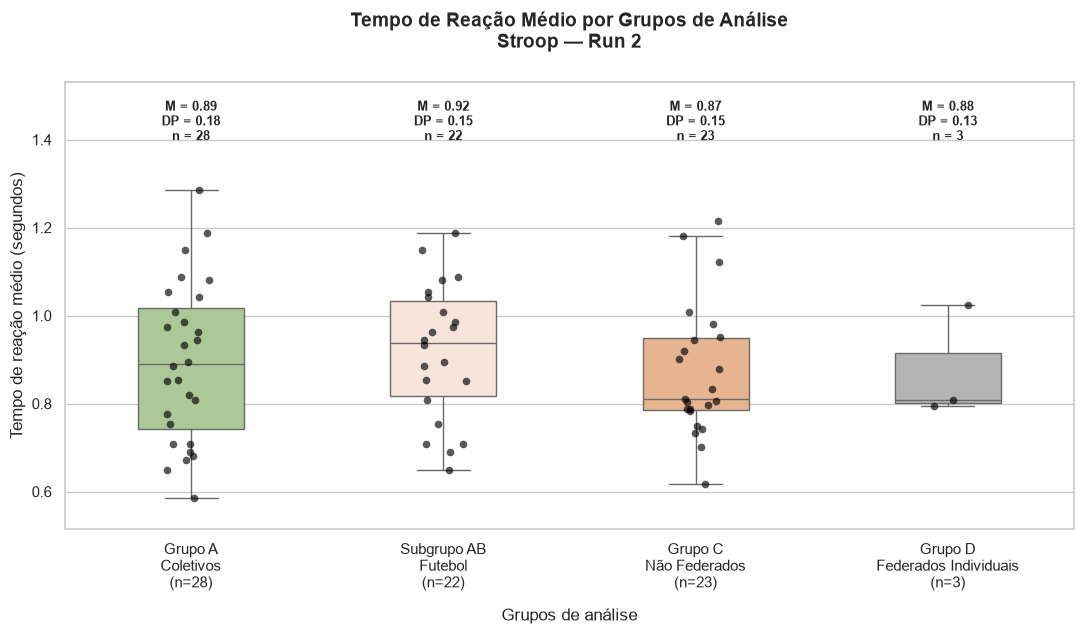


BOXPLOTS CONCLUÍDOS
Figuras guardadas em:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Boxplots_Comportamentais


,Tarefa_Run,Variavel,Medida,Grupo,N,Media,DP,Mediana,Minimo,Maximo
0,Decision Making — Run 1,DM_R1_Acc_Perc,Percentagem de Acerto,Grupo A Coletivos (n=28),28,57.50,13.51,60.00,30.00,90.00
1,Decision Making — Run 1,DM_R1_Acc_Perc,Percentagem de Acerto,Subgrupo AB Futebol (n=22),22,60.00,13.45,60.00,30.00,90.00
2,Decision Making — Run 1,DM_R1_Acc_Perc,Percentagem de Acerto,Grupo C Não Federados (n=23),23,50.87,18.57,50.00,10.00,80.00
3,Decision Making — Run 1,DM_R1_Acc_Perc,Percentagem de Acerto,Grupo D Federados Individuais (n=3),3,30.00,0.00,30.00,30.00,30.00
4,Decision Making — Run 1,DM_R1_Err_N,Número de Erros,Grupo A Coletivos (n=28),28,4.25,1.35,4.00,1.00,7.00
...,...,...,...,...,...,...,...,...,...,...
59,Stroop — Run 2,ST_R2_Omiss_N,Número de Omissões,Grupo D Federados Individuais (n=3),3,1.67,1.15,1.00,1.00,3.00
60,Stroop — Run 2,ST_R2_RT_Medio_seg,Tempo de Reação Médio,Grupo A Coletivos (n=28),28,0.89,0.18,0.89,0.59,1.29
61,Stroop — Run 2,ST_R2_RT_Medio_seg,Tempo de Reação Médio,Subgrupo AB Futebol (n=22),22,0.92,0.15,0.94,0.65,1.19
62,Stroop — Run 2,ST_R2_RT_Medio_seg,Tempo de Reação Médio,Grupo C Não Federados (n=23),23,0.87,0.15,0.81,0.62,1.21



Ficheiro de descritivos guardado em:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Descritivos_Comportamentais_por_Grupo.xlsx


In [8]:
# ==========================================================
# BOXPLOTS COMPORTAMENTAIS POR GRUPOS DE ANÁLISE
# Decision Making: Run 1 e Run 2
# Stroop: Run 1 e Run 2
# ==========================================================

from pathlib import Path
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ==========================================================
# 1. CARREGAR A BASE
# ==========================================================

pasta_dados = Path("../data_subjects")
ficheiro_merge = pasta_dados / "Merge_Dataset_Study_2.xlsx"
pasta_figuras = pasta_dados / "Boxplots_Comportamentais"

pasta_figuras.mkdir(exist_ok=True)

df = pd.read_excel(ficheiro_merge, sheet_name=0)

# Limpar espaços invisíveis dos nomes das colunas
df.columns = (
    df.columns
    .astype(str)
    .str.replace("\xa0", " ", regex=False)
    .str.strip()
)

print(f"Número total de participantes: {len(df)}")


# ==========================================================
# 2. FUNÇÃO PARA LIMPAR TEXTO
# ==========================================================

def limpar_texto(valor):
    """Remove espaços extra, acentos e uniformiza em minúsculas."""
    
    if pd.isna(valor):
        return ""

    texto = str(valor).replace("\xa0", " ").strip()
    texto = " ".join(texto.split())

    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(
        caractere
        for caractere in texto
        if unicodedata.category(caractere) != "Mn"
    )

    return texto.lower()


# ==========================================================
# 3. COLUNAS DA BASE
# ==========================================================

coluna_id = "ID"

coluna_estatuto = (
    "É atualmente praticante federado de alguma modalidade desportiva?"
)

coluna_modalidade = "Indique a modalidade principal"

# Confirma que as colunas essenciais existem
colunas_necessarias = [
    coluna_id,
    coluna_estatuto,
    coluna_modalidade
]

colunas_em_falta = [
    coluna
    for coluna in colunas_necessarias
    if coluna not in df.columns
]

if colunas_em_falta:
    raise KeyError(
        "Não foram encontradas estas colunas:\n"
        f"{colunas_em_falta}\n\n"
        f"Colunas disponíveis:\n{df.columns.tolist()}"
    )

# Criar versões limpas para fazer a classificação
df["Estatuto_limpo"] = df[coluna_estatuto].apply(limpar_texto)
df["Modalidade_limpa"] = df[coluna_modalidade].apply(limpar_texto)

print("\nValores de estatuto encontrados:")
print(sorted(df["Estatuto_limpo"].unique()))

print("\nModalidades encontradas:")
print(sorted(df["Modalidade_limpa"].unique()))


# ==========================================================
# 4. DEFINIR OS QUATRO GRUPOS
# ==========================================================

modalidades_coletivas = [
    "futebol",
    "futsal",
    "andebol",
    "voleibol"
]

# Grupo A: federados de modalidades coletivas
df_A = df.loc[
    (df["Estatuto_limpo"] == "sim")
    & (df["Modalidade_limpa"].isin(modalidades_coletivas))
].copy()

# Subgrupo AB: jogadores de futebol, incluídos também no Grupo A
df_AB = df_A.loc[
    df_A["Modalidade_limpa"] == "futebol"
].copy()

# Grupo C: não federados
df_C = df.loc[
    df["Estatuto_limpo"] == "nao"
].copy()

# Grupo D: federados de modalidade individual
df_D = df.loc[
    (df["Estatuto_limpo"] == "sim")
    & (~df["Modalidade_limpa"].isin(modalidades_coletivas))
].copy()

# Labels com as contagens reais
labels_grupos = {
    "A": f"Grupo A\nColetivos\n(n={len(df_A)})",
    "AB": f"Subgrupo AB\nFutebol\n(n={len(df_AB)})",
    "C": f"Grupo C\nNão Federados\n(n={len(df_C)})",
    "D": f"Grupo D\nFederados Individuais\n(n={len(df_D)})"
}

df_A["Grupo_Analise"] = labels_grupos["A"]
df_AB["Grupo_Analise"] = labels_grupos["AB"]
df_C["Grupo_Analise"] = labels_grupos["C"]
df_D["Grupo_Analise"] = labels_grupos["D"]

# Dataframe exclusivamente destinado à construção das figuras.
# Participantes de futebol surgem no Grupo A e também no Subgrupo AB.
df_grafico = pd.concat(
    [df_A, df_AB, df_C, df_D],
    ignore_index=True
)

ordem_grupos = [
    labels_grupos["A"],
    labels_grupos["AB"],
    labels_grupos["C"],
    labels_grupos["D"]
]

cores_grupos = {
    labels_grupos["A"]: "#A9D08E",
    labels_grupos["AB"]: "#FCE4D6",
    labels_grupos["C"]: "#F4B183",
    labels_grupos["D"]: "#B4B4B4"
}

print("\n" + "=" * 55)
print("VERIFICAÇÃO DAS CONTAGENS")
print("=" * 55)
print(f"Grupo A — Federados, modalidades coletivas: {len(df_A)}")
print(f"Subgrupo AB — Futebol: {len(df_AB)}")
print(f"Grupo C — Não Federados: {len(df_C)}")
print(f"Grupo D — Federados, modalidades individuais: {len(df_D)}")
print(f"Linhas no dataframe destinado aos gráficos: {len(df_grafico)}")
print("=" * 55)


# ==========================================================
# 5. DEFINIR AS VARIÁVEIS COMPORTAMENTAIS
# ==========================================================

runs = {
    "DM_R1": "Decision Making — Run 1",
    "DM_R2": "Decision Making — Run 2",
    "ST_R1": "Stroop — Run 1",
    "ST_R2": "Stroop — Run 2"
}

medidas = {
    "Acc_Perc": {
        "nome": "Percentagem de Acerto",
        "eixo_y": "Acerto (%)",
        "ficheiro": "acerto"
    },
    "Err_N": {
        "nome": "Número de Erros",
        "eixo_y": "Erros (n)",
        "ficheiro": "erros"
    },
    "Omiss_N": {
        "nome": "Número de Omissões",
        "eixo_y": "Omissões (n)",
        "ficheiro": "omissoes"
    },
    "RT_Medio_seg": {
        "nome": "Tempo de Reação Médio",
        "eixo_y": "Tempo de reação médio (segundos)",
        "ficheiro": "tempo_reacao"
    }
}

colunas_comportamentais = [
    f"{codigo_run}_{codigo_medida}"
    for codigo_run in runs
    for codigo_medida in medidas
]

colunas_comportamentais_faltam = [
    coluna
    for coluna in colunas_comportamentais
    if coluna not in df.columns
]

if colunas_comportamentais_faltam:
    raise KeyError(
        "Estas colunas comportamentais não foram encontradas:\n"
        f"{colunas_comportamentais_faltam}"
    )

# Converter variáveis comportamentais para numérico
for coluna in colunas_comportamentais:
    df_grafico[coluna] = pd.to_numeric(
        df_grafico[coluna],
        errors="coerce"
    )


# ==========================================================
# 6. FUNÇÃO PARA CRIAR UM BOXPLOT
# ==========================================================

sns.set_theme(style="whitegrid", context="notebook")

def criar_boxplot(
    dados,
    variavel,
    titulo_run,
    nome_medida,
    eixo_y,
    caminho_saida
):
    dados_plot = dados[
        ["Grupo_Analise", variavel]
    ].dropna().copy()

    if dados_plot.empty:
        print(f"Sem dados válidos para a variável: {variavel}")
        return

    maximo = dados_plot[variavel].max()
    minimo = dados_plot[variavel].min()
    amplitude = maximo - minimo

    if amplitude == 0:
        amplitude = 1

    margem_texto = amplitude * 0.15
    limite_superior = maximo + (amplitude * 0.35)

    # Acertos, erros e omissões começam em zero.
    if (
        "Acc_Perc" in variavel
        or "Err_N" in variavel
        or "Omiss_N" in variavel
    ):
        limite_inferior = 0
    else:
        limite_inferior = max(0, minimo - (amplitude * 0.10))

    fig, ax = plt.subplots(figsize=(11, 6.5))

    sns.boxplot(
        data=dados_plot,
        x="Grupo_Analise",
        y=variavel,
        hue="Grupo_Analise",
        order=ordem_grupos,
        hue_order=ordem_grupos,
        palette=cores_grupos,
        legend=False,
        width=0.42,
        fliersize=0,
        ax=ax
    )

    sns.stripplot(
        data=dados_plot,
        x="Grupo_Analise",
        y=variavel,
        order=ordem_grupos,
        color="black",
        alpha=0.65,
        size=5.5,
        jitter=0.10,
        ax=ax
    )

    # Adicionar média, DP e N válido por grupo
    for i, grupo in enumerate(ordem_grupos):

        valores = dados_plot.loc[
            dados_plot["Grupo_Analise"] == grupo,
            variavel
        ].dropna()

        if len(valores) == 0:
            continue

        media = valores.mean()
        dp = valores.std()

        ax.text(
            i,
            maximo + margem_texto,
            f"M = {media:.2f}\nDP = {dp:.2f}\nn = {len(valores)}",
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold"
        )

    ax.set_title(
        f"{nome_medida} por Grupos de Análise\n{titulo_run}",
        fontsize=14,
        fontweight="bold",
        pad=25
    )

    ax.set_xlabel("Grupos de análise", fontsize=12, labelpad=12)
    ax.set_ylabel(eixo_y, fontsize=12)
    ax.set_ylim(limite_inferior, limite_superior)
    ax.grid(axis="x", visible=False)

    plt.tight_layout()

    plt.savefig(
        caminho_saida,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ==========================================================
# 7. GERAR OS 16 BOXPLOTS
# ==========================================================

for codigo_run, titulo_run in runs.items():

    for codigo_medida, info_medida in medidas.items():

        coluna = f"{codigo_run}_{codigo_medida}"

        nome_ficheiro = (
            f"{codigo_run}_{info_medida['ficheiro']}_por_grupo.png"
        )

        criar_boxplot(
            dados=df_grafico,
            variavel=coluna,
            titulo_run=titulo_run,
            nome_medida=info_medida["nome"],
            eixo_y=info_medida["eixo_y"],
            caminho_saida=pasta_figuras / nome_ficheiro
        )

print("\n" + "=" * 55)
print("BOXPLOTS CONCLUÍDOS")
print(f"Figuras guardadas em:\n{pasta_figuras.resolve()}")
print("=" * 55)


# ==========================================================
# 8. EXPORTAR TABELA DE DESCRITIVOS
# ==========================================================

linhas_descritivas = []

for codigo_run, titulo_run in runs.items():

    for codigo_medida, info_medida in medidas.items():

        coluna = f"{codigo_run}_{codigo_medida}"

        for grupo in ordem_grupos:

            valores = df_grafico.loc[
                df_grafico["Grupo_Analise"] == grupo,
                coluna
            ].dropna()

            linhas_descritivas.append({
                "Tarefa_Run": titulo_run,
                "Variavel": coluna,
                "Medida": info_medida["nome"],
                "Grupo": grupo.replace("\n", " "),
                "N": len(valores),
                "Media": valores.mean(),
                "DP": valores.std(),
                "Mediana": valores.median(),
                "Minimo": valores.min(),
                "Maximo": valores.max()
            })

df_descritivos = pd.DataFrame(linhas_descritivas)

colunas_numericas = [
    "Media",
    "DP",
    "Mediana",
    "Minimo",
    "Maximo"
]

df_descritivos[colunas_numericas] = (
    df_descritivos[colunas_numericas].round(2)
)

ficheiro_descritivos = (
    pasta_dados / "Descritivos_Comportamentais_por_Grupo.xlsx"
)

df_descritivos.to_excel(
    ficheiro_descritivos,
    sheet_name="Descritivos",
    index=False
)

display(df_descritivos)

print(
    "\nFicheiro de descritivos guardado em:\n"
    f"{ficheiro_descritivos.resolve()}"
)

COMPARAÇÃO ENTRE GRUPOS

In [9]:
import sys
print(sys.executable)

c:\Users\guilh\miniconda3\envs\NIRS\python.exe


In [10]:
from scipy import stats
from statsmodels.stats.multitest import multipletests
import openpyxl

print("Tudo instalado corretamente.")

Tudo instalado corretamente.


In [11]:
from scipy import stats
from statsmodels.stats.multitest import multipletests
import openpyxl

print("SciPy, statsmodels e openpyxl carregados corretamente.")

SciPy, statsmodels e openpyxl carregados corretamente.


In [12]:
import pandas as pd
from pathlib import Path

FICHEIRO_DADOS = Path("../data_subjects/Merge_Dataset_Study_2.xlsx")

print("Ficheiro encontrado?", FICHEIRO_DADOS.exists())
print("Caminho absoluto:", FICHEIRO_DADOS.resolve())

df = pd.read_excel(
    FICHEIRO_DADOS,
    sheet_name="Merge Dataset"
)

print(f"\nBase carregada: {df.shape[0]} participantes × {df.shape[1]} colunas.")
display(df.head())

Ficheiro encontrado? True
Caminho absoluto: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Merge_Dataset_Study_2.xlsx

Base carregada: 54 participantes × 78 colunas.


,ID,Data da sessão,Mão Dominante,Data de nascimento,Sexo,Nacionalidade,Escolaridade,Situação/Ocupação Atual,É atualmente praticante federado de alguma modalidade desportiva?,"No caso de ser desportista federado, a sua modalidade principal é:",...,ST_R2_Acc_Perc,ST_R2_Acc_N,ST_R2_Err_N,ST_R2_Omiss_N,ST_R2_RT_Medio_seg,ST_Acc_N_Total,ST_RT_Medio_Total_seg,ST_R2_RT_Min_seg,ST_R2_RT_Max_seg,origem_merge
0,sub-001,2026-08-04,Direita,2003-03-03,Feminino,Portuguesa,Licenciatura,Estudante,Não,NaN,...,91.67,55,2,3,1.213822,107,1.195578,0.744377,1.686847,both
1,sub-002,2026-07-28,Direita,1996-04-17,Masculino,Portuguesa,Licenciatura,Estudante,Não,NaN,...,100.00,60,0,0,0.951753,114,1.013062,0.655949,1.556367,both
2,sub-003,2026-07-28,Direita,2000-08-26,Masculino,Portuguesa,Mestrado,Empregado,Sim,Modalidade Coletiva,...,91.67,55,2,3,1.088445,100,1.126584,0.623281,1.656173,both
3,sub-004,2026-07-29,Direita,1997-04-19,Masculino,Portuguesa,Mestrado,Trabalhador-Estudante,Não,NaN,...,90.00,54,3,3,1.180344,107,1.185439,0.742189,1.701297,both
4,sub-005,2026-07-30,Direita,1987-02-17,Masculino,Portuguesa,Doutoramento,Empregado,Não,NaN,...,75.00,45,15,0,0.741367,89,0.735760,0.575416,1.259819,both


Pressupostos Testes a utilizar

In [13]:
# ==========================================================
# RECARREGAR A BASE APÓS RESTART DO KERNEL
# ==========================================================

from pathlib import Path
import pandas as pd
from IPython.display import display


NOME_FICHEIRO = "Merge_Dataset_Study_2.xlsx"

PASTA_DATA = Path(
    r"C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects"
)

CAMINHO_BASE = PASTA_DATA / NOME_FICHEIRO


# 1. Procurar na pasta data_subjects e respetivas subpastas
if not CAMINHO_BASE.is_file():
    encontrados = (
        list(PASTA_DATA.rglob(NOME_FICHEIRO))
        if PASTA_DATA.is_dir()
        else []
    )

    if len(encontrados) == 1:
        CAMINHO_BASE = encontrados[0]

    else:
        # Seleção manual se não existir uma correspondência única
        import tkinter as tk
        from tkinter import filedialog

        janela = tk.Tk()
        janela.withdraw()

        try:
            selecionado = filedialog.askopenfilename(
                title="Seleciona Merge_Dataset_Study_2.xlsx",
                initialdir=str(
                    PASTA_DATA if PASTA_DATA.is_dir() else Path.home()
                ),
                filetypes=[("Ficheiros Excel", "*.xlsx")]
            )
        finally:
            janela.destroy()

        if not selecionado:
            raise FileNotFoundError(
                "Nenhum ficheiro selecionado. "
                "Volta a executar esta célula e seleciona a base."
            )

        CAMINHO_BASE = Path(selecionado)


# 2. Ler a folha da base
with pd.ExcelFile(CAMINHO_BASE, engine="openpyxl") as excel:
    if "Merge Dataset" not in excel.sheet_names:
        raise ValueError(
            "Não foi encontrada a folha 'Merge Dataset'. "
            f"Folhas disponíveis: {excel.sheet_names}"
        )

    df_carregado = pd.read_excel(
        excel,
        sheet_name="Merge Dataset"
    )


# 3. Uniformizar os nomes das colunas
df_carregado.columns = [
    " ".join(str(c).replace("\xa0", " ").strip().split())
    for c in df_carregado.columns
]


# 4. Confirmar as colunas necessárias à análise por run
colunas_necessarias = [
    "ID",
    "É atualmente praticante federado de alguma modalidade desportiva?",
    "Indique a modalidade principal",
    "ST_R1_Acc_Perc",
    "ST_R1_RT_Medio_seg",
    "ST_R2_Acc_Perc",
    "ST_R2_RT_Medio_seg",
    "DM_R1_Acc_Perc",
    "DM_R1_RT_Medio_seg",
    "DM_R2_Acc_Perc",
    "DM_R2_RT_Medio_seg"
]

em_falta = [
    coluna
    for coluna in colunas_necessarias
    if coluna not in df_carregado.columns
]

if em_falta:
    raise KeyError(
        "Faltam as seguintes colunas:\n- "
        + "\n- ".join(em_falta)
    )

if df_carregado["ID"].isna().any():
    raise ValueError("Existem participantes sem ID.")

if df_carregado["ID"].duplicated().any():
    duplicados = df_carregado.loc[
        df_carregado["ID"].duplicated(keep=False),
        "ID"
    ].tolist()

    raise ValueError(f"Existem IDs duplicados: {duplicados}")


# 5. Disponibilizar o dataframe utilizado no script seguinte
df = df_carregado.copy()

print("=" * 65)
print("BASE CARREGADA")
print("=" * 65)
print(f"Ficheiro: {CAMINHO_BASE.resolve()}")
print(f"Participantes: {len(df)}")
print(f"Colunas: {len(df.columns)}")
print(f"\nPasta atual do notebook: {Path.cwd()}")
print(
    "\nDestino previsto pelo script de análise:\n"
    f"{Path('../data_subjects/Analises_Estatisticas_Grupos').resolve()}"
)

display(df[colunas_necessarias].head())

BASE CARREGADA
Ficheiro: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Merge_Dataset_Study_2.xlsx
Participantes: 54
Colunas: 78

Pasta atual do notebook: c:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\scripts

Destino previsto pelo script de análise:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Analises_Estatisticas_Grupos


,ID,É atualmente praticante federado de alguma modalidade desportiva?,Indique a modalidade principal,ST_R1_Acc_Perc,ST_R1_RT_Medio_seg,ST_R2_Acc_Perc,ST_R2_RT_Medio_seg,DM_R1_Acc_Perc,DM_R1_RT_Medio_seg,DM_R2_Acc_Perc,DM_R2_RT_Medio_seg
0,sub-001,Não,NaN,86.67,1.177334,91.67,1.213822,30,1.045299,50,1.369989
1,sub-002,Não,NaN,90.00,1.074371,100.00,0.951753,70,1.523610,30,1.035069
2,sub-003,Sim,Futebol,75.00,1.164723,91.67,1.088445,60,0.703181,40,0.494681
3,sub-004,Não,NaN,88.33,1.190534,90.00,1.180344,40,0.820973,60,0.740595
4,sub-005,Não,NaN,73.33,0.730152,75.00,0.741367,70,1.514799,50,0.701018


In [14]:
# ==========================================================
# COMPARAÇÕES ENTRE GRUPOS — RESULTADOS POR RUN
#
# Diagnósticos:
# - Descritivos e dados omissos
# - Shapiro–Wilk por variável e grupo
# - Brown–Forsythe: Levene centrado na mediana
# - Histogramas, Q-Q plots e boxplots
# - Valores extremos pelo critério de 1.5 x IQR
#
# Inferência:
# - Teste t de Welch bilateral
# - IC95% analítico da diferença média
# - Hedges g com correção aproximada de Hedges
# - IC95% bootstrap percentil da diferença média e de g
# - Holm aplicado conjuntamente aos 16 testes de Welch
#
# IMPORTANTE:
# - Não são excluídos valores extremos automaticamente.
# - Os diagnósticos não selecionam automaticamente outro teste.
# - Bootstrap fornece IC complementares, não um teste de
#   sensibilidade independente nem garantia de robustez.
# - A pasta de saída é apagada e recriada em cada execução.
# ==========================================================

from pathlib import Path
import shutil
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.multitest import multipletests
from openpyxl.styles import Font, PatternFill, Alignment
from IPython.display import display


# ==========================================================
# 1. CONFIGURAÇÃO
# ==========================================================

ALPHA = 0.05
N_BOOTSTRAP = 10000
SEMENTE = 20261102

PASTA_BASE = Path("../data_subjects").resolve()
PASTA_SAIDA = PASTA_BASE / "Analises_Estatisticas_Grupos"
PASTA_GRAFICOS = PASTA_SAIDA / "Diagnosticos_Graficos"

COL_ESTATUTO = (
    "É atualmente praticante federado de alguma modalidade desportiva?"
)
COL_MODALIDADE = "Indique a modalidade principal"

MODALIDADES_COLETIVAS = {
    "futebol", "futsal", "andebol", "voleibol"
}

VARIAVEIS = {
    "ST_R1_Acc_Perc": "Stroop — Run 1: Acerto (%)",
    "ST_R1_RT_Medio_seg": "Stroop — Run 1: TR médio (s)",
    "ST_R2_Acc_Perc": "Stroop — Run 2: Acerto (%)",
    "ST_R2_RT_Medio_seg": "Stroop — Run 2: TR médio (s)",
    "DM_R1_Acc_Perc": "Decision Making — Run 1: Acerto (%)",
    "DM_R1_RT_Medio_seg": "Decision Making — Run 1: TR médio (s)",
    "DM_R2_Acc_Perc": "Decision Making — Run 2: Acerto (%)",
    "DM_R2_RT_Medio_seg": "Decision Making — Run 2: TR médio (s)"
}


# ==========================================================
# 2. FUNÇÕES AUXILIARES
# ==========================================================

def limpar_texto(valor):
    if pd.isna(valor):
        return ""

    texto = " ".join(
        str(valor).replace("\xa0", " ").strip().split()
    )
    texto = unicodedata.normalize("NFD", texto)

    return "".join(
        c for c in texto
        if unicodedata.category(c) != "Mn"
    ).lower()


def hedges_g(x, y):
    n1, n2 = len(x), len(y)
    gl = n1 + n2 - 2

    variancia_combinada = (
        (n1 - 1) * np.var(x, ddof=1)
        + (n2 - 1) * np.var(y, ddof=1)
    ) / gl

    if not np.isfinite(variancia_combinada):
        return np.nan

    if variancia_combinada <= 0:
        return np.nan

    d = (
        np.mean(x) - np.mean(y)
    ) / np.sqrt(variancia_combinada)

    correcao = 1 - 3 / (4 * gl - 1)

    return correcao * d


def bootstrap_ic(x, y, rng):
    diferencas = np.empty(N_BOOTSTRAP)
    efeitos = np.empty(N_BOOTSTRAP)

    for i in range(N_BOOTSTRAP):
        xb = rng.choice(x, size=len(x), replace=True)
        yb = rng.choice(y, size=len(y), replace=True)

        diferencas[i] = np.mean(xb) - np.mean(yb)
        efeitos[i] = hedges_g(xb, yb)

    efeitos_validos = efeitos[np.isfinite(efeitos)]

    ic_diferenca = np.percentile(
        diferencas, [2.5, 97.5]
    )

    if len(efeitos_validos) >= 2:
        ic_g = np.percentile(
            efeitos_validos, [2.5, 97.5]
        )
    else:
        ic_g = np.array([np.nan, np.nan])

    return ic_diferenca, ic_g, len(efeitos_validos)


def shapiro_seguro(x):
    if len(x) < 3:
        return np.nan, np.nan, "Menos de 3 valores"

    if np.ptp(x) == 0:
        return np.nan, np.nan, "Variável constante"

    resultado = stats.shapiro(x)

    return resultado.statistic, resultado.pvalue, "Calculado"


def brown_forsythe_seguro(x, y):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        resultado = stats.levene(x, y, center="median")

    return resultado.statistic, resultado.pvalue


def formatar_p(p):
    if not np.isfinite(p):
        return ""

    if p < 0.001:
        return "< .001"

    return f"{p:.3f}".replace("0.", ".")


def diagnostico_grafico(x, grupo, rotulo, caminho):
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))

    eixos[0].hist(
        x,
        bins="auto",
        color="#3B82B6",
        edgecolor="white"
    )
    eixos[0].set_title("Histograma")
    eixos[0].set_xlabel("Valor")
    eixos[0].set_ylabel("Frequência")

    if np.ptp(x) > 0:
        stats.probplot(x, dist="norm", plot=eixos[1])
    else:
        eixos[1].text(
            0.5, 0.5,
            "Variável constante:\nQ-Q não informativo",
            ha="center",
            va="center",
            transform=eixos[1].transAxes
        )

    eixos[1].set_title("Q-Q normal")
    eixos[1].set_xlabel("Quantis teóricos")
    eixos[1].set_ylabel("Quantis observados")

    eixos[2].boxplot(x, showfliers=True)

    rng_plot = np.random.default_rng(SEMENTE)
    eixos[2].scatter(
        rng_plot.normal(1, 0.035, len(x)),
        x,
        color="black",
        alpha=0.55,
        s=20,
        zorder=3
    )

    eixos[2].set_xticks([1])
    eixos[2].set_xticklabels([grupo])
    eixos[2].set_title("Boxplot e valores individuais")
    eixos[2].set_ylabel("Valor")

    fig.suptitle(
        f"{rotulo}\n{grupo}",
        fontweight="bold"
    )

    fig.tight_layout()

    try:
        fig.savefig(
            caminho,
            dpi=300,
            bbox_inches="tight"
        )
    finally:
        plt.close(fig)


# ==========================================================
# 3. VALIDAR O DATAFRAME ANTES DE APAGAR RESULTADOS
# ==========================================================

if "df" not in globals():
    raise NameError(
        "O dataframe 'df' não existe. "
        "Executa primeiro a célula que carrega a base."
    )

if not isinstance(df, pd.DataFrame):
    raise TypeError("'df' tem de ser um dataframe pandas.")

dados = df.copy()

dados.columns = [
    " ".join(str(c).replace("\xa0", " ").strip().split())
    for c in dados.columns
]

if dados.columns.duplicated().any():
    raise ValueError(
        "Existem nomes de colunas duplicados após a limpeza."
    )

necessarias = [
    COL_ESTATUTO,
    COL_MODALIDADE,
    *VARIAVEIS.keys()
]

em_falta = [c for c in necessarias if c not in dados.columns]

if em_falta:
    raise KeyError(
        "Colunas em falta:\n- " + "\n- ".join(em_falta)
    )

dados["_linha_dataframe"] = np.arange(len(dados))

if "ID" in dados.columns:
    dados["_identificador"] = dados["ID"].astype(str)
else:
    dados["_identificador"] = [
        f"linha_posicional_{i}" for i in range(len(dados))
    ]

dados["_estatuto"] = dados[COL_ESTATUTO].apply(limpar_texto)
dados["_modalidade"] = dados[COL_MODALIDADE].apply(limpar_texto)

problemas = []

for coluna, rotulo in VARIAVEIS.items():
    original = dados[coluna]

    numerico = pd.to_numeric(
        original,
        errors="coerce"
    ).astype(float)

    conversao_invalida = original.notna() & numerico.isna()
    infinito = numerico.notna() & ~np.isfinite(numerico)

    if coluna.endswith("_Acc_Perc"):
        fora_intervalo = numerico.notna() & (
            (numerico < 0) | (numerico > 100)
        )
    else:
        fora_intervalo = numerico.notna() & (numerico <= 0)

    tipos = {
        "Valor não numérico": conversao_invalida,
        "Valor infinito": infinito,
        "Valor fora do domínio esperado": fora_intervalo
    }

    for motivo, mascara in tipos.items():
        for _, linha in dados.loc[mascara].iterrows():
            problemas.append({
                "ID": linha["_identificador"],
                "Variável": coluna,
                "Valor": linha[coluna],
                "Problema": motivo
            })

    dados[coluna] = numerico

if problemas:
    display(pd.DataFrame(problemas))
    raise ValueError(
        "Foram encontrados valores inválidos. "
        "Revê a tabela acima antes da análise. "
        "A pasta anterior não foi apagada."
    )


# ==========================================================
# 4. GRUPOS E CONTRASTES
# ==========================================================

mascara_A = (
    dados["_estatuto"].eq("sim")
    & dados["_modalidade"].isin(MODALIDADES_COLETIVAS)
)

mascara_AB = (
    mascara_A
    & dados["_modalidade"].eq("futebol")
)

mascara_C = dados["_estatuto"].eq("nao")

GRUPOS = {
    "A": {
        "nome": "Grupo A — Coletivos",
        "dados": dados.loc[mascara_A].copy()
    },
    "AB": {
        "nome": "Subgrupo AB — Futebol",
        "dados": dados.loc[mascara_AB].copy()
    },
    "C": {
        "nome": "Grupo C — Não federados",
        "dados": dados.loc[mascara_C].copy()
    }
}

CONTRASTES = {
    "A vs C": ("A", "C"),
    "AB vs C": ("AB", "C")
}

for codigo, grupo in GRUPOS.items():
    for coluna in VARIAVEIS:
        n_valido = grupo["dados"][coluna].notna().sum()

        if n_valido < 3:
            raise ValueError(
                f"{codigo}: apenas {n_valido} valores válidos "
                f"para {coluna}. A pasta anterior foi preservada."
            )

for coluna in VARIAVEIS:
    for contraste, (g1, g2) in CONTRASTES.items():
        x = GRUPOS[g1]["dados"][coluna].dropna().to_numpy()
        y = GRUPOS[g2]["dados"][coluna].dropna().to_numpy()

        if np.var(x, ddof=1) + np.var(y, ddof=1) == 0:
            raise ValueError(
                f"Variância nula nos dois grupos: "
                f"{coluna}, {contraste}. "
                "O teste de Welch não pode ser calculado."
            )


# ==========================================================
# 5. SUBSTITUIR A PASTA DE RESULTADOS
# ==========================================================

if (
    PASTA_SAIDA.parent != PASTA_BASE
    or PASTA_SAIDA.name != "Analises_Estatisticas_Grupos"
):
    raise RuntimeError("Caminho de saída não autorizado.")

if PASTA_SAIDA.is_symlink():
    raise RuntimeError(
        "A pasta de saída é uma ligação simbólica. "
        "A eliminação foi cancelada."
    )

if PASTA_SAIDA.exists():
    if not PASTA_SAIDA.is_dir():
        raise RuntimeError(
            "O caminho de saída existe, mas não é uma pasta."
        )

    try:
        shutil.rmtree(PASTA_SAIDA)
    except PermissionError as erro:
        raise PermissionError(
            "Não foi possível apagar a pasta anterior. "
            "Fecha o Excel e outros ficheiros de resultados "
            "e volta a executar o bloco completo."
        ) from erro

PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)


# ==========================================================
# 6. DESCRITIVOS E DIAGNÓSTICOS POR GRUPO
# ==========================================================

descritivos = []
normalidade = []
extremos = []
cache = {}

for coluna, rotulo in VARIAVEIS.items():
    for codigo, grupo in GRUPOS.items():
        base = grupo["dados"]
        validos = base.loc[base[coluna].notna()].copy()
        x = validos[coluna].to_numpy(dtype=float)

        cache[(coluna, codigo)] = x

        q1, mediana, q3 = np.percentile(x, [25, 50, 75])
        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        mascara_extremos = (
            (x < limite_inferior)
            | (x > limite_superior)
        )

        descritivos.append({
            "Variável código": coluna,
            "Variável": rotulo,
            "Grupo": grupo["nome"],
            "n total": len(base),
            "n válido": len(x),
            "n omisso": len(base) - len(x),
            "Média": np.mean(x),
            "DP": np.std(x, ddof=1),
            "Mediana": mediana,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Mínimo": np.min(x),
            "Máximo": np.max(x),
            "Assimetria": (
                stats.skew(x, bias=False)
                if np.ptp(x) > 0 else np.nan
            ),
            "n extremos IQR": int(mascara_extremos.sum()),
            "IQR nulo": "Sim" if iqr == 0 else "Não"
        })

        w, p, estado = shapiro_seguro(x)

        normalidade.append({
            "Variável código": coluna,
            "Variável": rotulo,
            "Grupo": grupo["nome"],
            "n": len(x),
            "Shapiro W": w,
            "p Shapiro": p,
            "Estado": estado
        })

        for posicao in np.flatnonzero(mascara_extremos):
            linha = validos.iloc[posicao]

            extremos.append({
                "Variável código": coluna,
                "Variável": rotulo,
                "Grupo": grupo["nome"],
                "ID": linha["_identificador"],
                "Linha posicional df": linha["_linha_dataframe"],
                "Valor": x[posicao],
                "Limite inferior": limite_inferior,
                "Limite superior": limite_superior,
                "IQR nulo": "Sim" if iqr == 0 else "Não",
                "Excluído": "Não"
            })

        diagnostico_grafico(
            x,
            grupo["nome"],
            rotulo,
            PASTA_GRAFICOS / f"{coluna}_{codigo}.png"
        )


# ==========================================================
# 7. WELCH, BROWN–FORSYTHE E BOOTSTRAP
# ==========================================================

rng = np.random.default_rng(SEMENTE)

resultados = []
variancias = []

for coluna, rotulo in VARIAVEIS.items():
    for contraste, (g1, g2) in CONTRASTES.items():
        x = cache[(coluna, g1)]
        y = cache[(coluna, g2)]

        n1, n2 = len(x), len(y)
        v1 = np.var(x, ddof=1)
        v2 = np.var(y, ddof=1)

        f_bf, p_bf = brown_forsythe_seguro(x, y)

        variancias.append({
            "Variável": rotulo,
            "Contraste": contraste,
            "DP1": np.sqrt(v1),
            "DP2": np.sqrt(v2),
            "Brown-Forsythe F": f_bf,
            "p Brown-Forsythe": p_bf
        })

        teste = stats.ttest_ind(
            x, y,
            equal_var=False,
            alternative="two-sided"
        )

        erro_quadrado = v1 / n1 + v2 / n2

        gl = erro_quadrado ** 2 / (
            (v1 / n1) ** 2 / (n1 - 1)
            + (v2 / n2) ** 2 / (n2 - 1)
        )

        diferenca = np.mean(x) - np.mean(y)
        margem = stats.t.ppf(
            1 - ALPHA / 2, gl
        ) * np.sqrt(erro_quadrado)

        ic_boot, ic_g, n_g_validos = bootstrap_ic(x, y, rng)

        resultados.append({
            "Variável código": coluna,
            "Variável": rotulo,
            "Contraste": contraste,
            "Grupo 1": GRUPOS[g1]["nome"],
            "Grupo 2": GRUPOS[g2]["nome"],
            "n1": n1,
            "M1": np.mean(x),
            "DP1": np.std(x, ddof=1),
            "n2": n2,
            "M2": np.mean(y),
            "DP2": np.std(y, ddof=1),
            "Diferença média G1-G2": diferenca,
            "IC95% diferença inferior": diferenca - margem,
            "IC95% diferença superior": diferenca + margem,
            "t Welch": teste.statistic,
            "gl Welch": gl,
            "p não corrigido": teste.pvalue,
            "Hedges g": hedges_g(x, y),
            "IC95% g bootstrap inferior": ic_g[0],
            "IC95% g bootstrap superior": ic_g[1],
            "IC95% diferença bootstrap inferior": ic_boot[0],
            "IC95% diferença bootstrap superior": ic_boot[1],
            "Bootstrap g válidos": n_g_validos,
            "Bootstrap total": N_BOOTSTRAP
        })


# ==========================================================
# 8. HOLM — UMA FAMÍLIA DE 16 TESTES
# ==========================================================

df_resultados = pd.DataFrame(resultados)

if len(df_resultados) != 16:
    raise RuntimeError("Esperavam-se exatamente 16 comparações.")

if not np.isfinite(df_resultados["p não corrigido"]).all():
    raise RuntimeError(
        "Existem testes de Welch com p inválido. "
        "A correção de Holm não foi aplicada."
    )

rejeitar, p_holm, _, _ = multipletests(
    df_resultados["p não corrigido"].to_numpy(),
    alpha=ALPHA,
    method="holm"
)

df_resultados["p Holm"] = p_holm
df_resultados["Significativo após Holm"] = np.where(
    rejeitar, "Sim", "Não"
)

df_descritivos = pd.DataFrame(descritivos)
df_normalidade = pd.DataFrame(normalidade)
df_variancias = pd.DataFrame(variancias)

df_extremos = pd.DataFrame(
    extremos,
    columns=[
        "Variável código",
        "Variável",
        "Grupo",
        "ID",
        "Linha posicional df",
        "Valor",
        "Limite inferior",
        "Limite superior",
        "IQR nulo",
        "Excluído"
    ]
)

tabela_artigo = df_resultados[
    [
        "Variável", "Contraste",
        "n1", "M1", "DP1",
        "n2", "M2", "DP2",
        "Diferença média G1-G2",
        "IC95% diferença inferior",
        "IC95% diferença superior",
        "t Welch", "gl Welch",
        "p não corrigido", "p Holm",
        "Hedges g",
        "IC95% g bootstrap inferior",
        "IC95% g bootstrap superior",
        "Significativo após Holm"
    ]
].copy()

colunas_numericas = tabela_artigo.select_dtypes(
    include="number"
).columns

tabela_artigo[colunas_numericas] = (
    tabela_artigo[colunas_numericas].round(3)
)

for coluna in ["p não corrigido", "p Holm"]:
    tabela_artigo[coluna] = (
        df_resultados[coluna].apply(formatar_p)
    )


# ==========================================================
# 9. DOCUMENTAÇÃO DA ANÁLISE
# ==========================================================

notas = [
    (
        "Análise",
        "Comparações entre grupos separadamente em cada run."
    ),
    (
        "Grupo A",
        "Federados atuais em futebol, futsal, andebol ou voleibol."
    ),
    (
        "Subgrupo AB",
        "Participantes do Grupo A cuja modalidade é futebol."
    ),
    (
        "Grupo C",
        "Participantes não federados atualmente."
    ),
    (
        "Sobreposição",
        "AB é subconjunto de A; os contrastes não são independentes."
    ),
    (
        "Dados omissos",
        "Análise por casos disponíveis em cada variável; sem imputação."
    ),
    (
        "Normalidade",
        "Shapiro–Wilk e gráficos por grupo e variável; "
        "não usados como seleção automática do teste."
    ),
    (
        "Variâncias",
        "Brown–Forsythe: scipy.stats.levene com center='median'."
    ),
    (
        "Diagnósticos p",
        "Valores p diagnósticos não corrigidos; "
        "não representam decisões confirmatórias."
    ),
    (
        "Extremos",
        "Valores abaixo de Q1-1.5*IQR ou acima de Q3+1.5*IQR; "
        "nenhuma exclusão automática. Com IQR nulo, "
        "o critério pode sinalizar muitos valores."
    ),
    (
        "Independência",
        "A independência entre participantes depende do desenho; "
        "não é demonstrada pelos testes diagnósticos."
    ),
    (
        "Welch",
        "Teste bilateral de médias para amostras independentes; "
        "não pressupõe igualdade de variâncias."
    ),
    (
        "IC diferença",
        "IC95% analítico de Welch–Satterthwaite."
    ),
    (
        "Hedges g",
        "Diferença G1-G2 dividida pelo DP combinado, "
        "com J aproximado = 1-3/[4*(n1+n2-2)-1]."
    ),
    (
        "Bootstrap",
        f"Percentil; {N_BOOTSTRAP} reamostragens independentes "
        f"dentro de cada grupo; semente {SEMENTE}."
    ),
    (
        "Bootstrap degenerado",
        "Reamostragens com g indefinido não entram no seu IC; "
        "o número de reamostragens válidas é apresentado."
    ),
    (
        "Limite bootstrap",
        "Os IC bootstrap são complementares; não validam "
        "automaticamente o teste de Welch."
    ),
    (
        "Multiplicidade",
        "Holm aplicado conjuntamente aos 16 testes de Welch; "
        "alfa familiar = .05."
    ),
    (
        "Intervalos de confiança",
        "IC individuais de 95%, não ajustados para multiplicidade."
    ),
    (
        "Direção",
        "G1-G2; valor positivo significa média superior em G1. "
        "Nos TR, um valor negativo indica G1 mais rápido."
    ),
    (
        "Acerto",
        "Diferenças de acerto expressas em pontos percentuais."
    ),
    (
        "Interação",
        "Este script não testa interação grupo x run."
    ),
    (
        "Interpretação",
        "Os diagnósticos e gráficos exigem apreciação conjunta; "
        "não é emitida uma aprovação automática dos pressupostos."
    )
]

df_notas = pd.DataFrame(notas, columns=["Item", "Descrição"])

import sys
import scipy
import statsmodels
import matplotlib
import openpyxl

df_software = pd.DataFrame({
    "Software": [
        "Python", "numpy", "pandas", "scipy",
        "statsmodels", "matplotlib", "openpyxl"
    ],
    "Versão": [
        sys.version.split()[0],
        np.__version__,
        pd.__version__,
        scipy.__version__,
        statsmodels.__version__,
        matplotlib.__version__,
        openpyxl.__version__
    ]
})


# ==========================================================
# 10. EXPORTAR EXCEL E CSVs NUMÉRICOS
# ==========================================================

ficheiro_excel = (
    PASTA_SAIDA / "Resultados_Welch_HedgesG_Holm.xlsx"
)

folhas = {
    "1_Descritivos": df_descritivos,
    "2_Normalidade": df_normalidade,
    "3_Variancias": df_variancias,
    "4_Extremos_IQR": df_extremos,
    "5_Resultados_Numericos": df_resultados,
    "6_Tabela_Artigo": tabela_artigo,
    "7_Notas_Metodologicas": df_notas,
    "8_Software": df_software
}

with pd.ExcelWriter(
    ficheiro_excel,
    engine="openpyxl"
) as writer:

    for nome, tabela in folhas.items():
        tabela.to_excel(writer, sheet_name=nome, index=False)

        ws = writer.sheets[nome]
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        for celula in ws[1]:
            celula.font = Font(bold=True, color="FFFFFF")
            celula.fill = PatternFill(
                fill_type="solid",
                fgColor="1F4E78"
            )
            celula.alignment = Alignment(
                wrap_text=True,
                vertical="center"
            )

        for coluna in ws.columns:
            largura = max(
                len(str(c.value)) if c.value is not None else 0
                for c in coluna
            )
            ws.column_dimensions[
                coluna[0].column_letter
            ].width = min(largura + 2, 55)

df_resultados.to_csv(
    PASTA_SAIDA / "Resultados_Numericos.csv",
    index=False,
    encoding="utf-8-sig"
)

df_descritivos.to_csv(
    PASTA_SAIDA / "Descritivos.csv",
    index=False,
    encoding="utf-8-sig"
)

df_normalidade.to_csv(
    PASTA_SAIDA / "Normalidade.csv",
    index=False,
    encoding="utf-8-sig"
)

df_variancias.to_csv(
    PASTA_SAIDA / "Variancias.csv",
    index=False,
    encoding="utf-8-sig"
)

df_extremos.to_csv(
    PASTA_SAIDA / "Extremos_IQR.csv",
    index=False,
    encoding="utf-8-sig"
)


# ==========================================================
# 11. CONFIRMAÇÃO FINAL
# ==========================================================

print("=" * 70)
print("ANÁLISE POR RUN CONCLUÍDA")
print("=" * 70)

for codigo, grupo in GRUPOS.items():
    print(f"{codigo}: {len(grupo['dados'])} participantes")

print(f"\nComparações de Welch: {len(df_resultados)}")
print("Correção: Holm, uma família de 16 testes")
print(
    "Painéis gráficos criados: "
    f"{len(list(PASTA_GRAFICOS.glob('*.png')))}"
)
print(f"\nExcel:\n{ficheiro_excel}")
print(f"\nGráficos:\n{PASTA_GRAFICOS}")

print(
    "\nNenhuma observação foi excluída pelo critério de extremos."
)
print(
    "Os resultados diagnósticos não constituem uma "
    "aprovação automática dos pressupostos."
)

print("\nNORMALIDADE:")
display(df_normalidade.round(4))

print("\nVARIÂNCIAS:")
display(df_variancias.round(4))

print("\nRESULTADOS:")
display(tabela_artigo)

ANÁLISE POR RUN CONCLUÍDA
A: 28 participantes
AB: 22 participantes
C: 23 participantes

Comparações de Welch: 16
Correção: Holm, uma família de 16 testes
Painéis gráficos criados: 24

Excel:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Analises_Estatisticas_Grupos\Resultados_Welch_HedgesG_Holm.xlsx

Gráficos:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Analises_Estatisticas_Grupos\Diagnosticos_Graficos

Nenhuma observação foi excluída pelo critério de extremos.
Os resultados diagnósticos não constituem uma aprovação automática dos pressupostos.

NORMALIDADE:


,Variável código,Variável,Grupo,n,Shapiro W,p Shapiro,Estado
0,ST_R1_Acc_Perc,Stroop — Run 1: Acerto (%),Grupo A — Coletivos,28,0.5641,0.0000,Calculado
1,ST_R1_Acc_Perc,Stroop — Run 1: Acerto (%),Subgrupo AB — Futebol,22,0.7945,0.0004,Calculado
2,ST_R1_Acc_Perc,Stroop — Run 1: Acerto (%),Grupo C — Não federados,23,0.9001,0.0253,Calculado
3,ST_R1_RT_Medio_seg,Stroop — Run 1: TR médio (s),Grupo A — Coletivos,28,0.9352,0.0833,Calculado
4,ST_R1_RT_Medio_seg,Stroop — Run 1: TR médio (s),Subgrupo AB — Futebol,22,0.9448,0.2482,Calculado
5,ST_R1_RT_Medio_seg,Stroop — Run 1: TR médio (s),Grupo C — Não federados,23,0.9604,0.4719,Calculado
6,ST_R2_Acc_Perc,Stroop — Run 2: Acerto (%),Grupo A — Coletivos,28,0.3810,0.0000,Calculado
7,ST_R2_Acc_Perc,Stroop — Run 2: Acerto (%),Subgrupo AB — Futebol,22,0.6277,0.0000,Calculado
8,ST_R2_Acc_Perc,Stroop — Run 2: Acerto (%),Grupo C — Não federados,23,0.7858,0.0002,Calculado
9,ST_R2_RT_Medio_seg,Stroop — Run 2: TR médio (s),Grupo A — Coletivos,28,0.9775,0.7869,Calculado



VARIÂNCIAS:


,Variável,Contraste,DP1,DP2,Brown-Forsythe F,p Brown-Forsythe
0,Stroop — Run 1: Acerto (%),A vs C,18.8674,6.7798,0.9634,0.3312
1,Stroop — Run 1: Acerto (%),AB vs C,9.0308,6.7798,0.1525,0.6981
2,Stroop — Run 1: TR médio (s),A vs C,0.1587,0.1277,1.1200,0.2951
3,Stroop — Run 1: TR médio (s),AB vs C,0.1396,0.1277,0.3233,0.5726
4,Stroop — Run 2: Acerto (%),A vs C,18.8484,5.6851,0.4726,0.4950
5,Stroop — Run 2: Acerto (%),AB vs C,5.1292,5.6851,0.5977,0.4437
6,Stroop — Run 2: TR médio (s),A vs C,0.1798,0.1519,1.2908,0.2614
7,Stroop — Run 2: TR médio (s),AB vs C,0.1540,0.1519,0.1194,0.7314
8,Decision Making — Run 1: Acerto (%),A vs C,13.5058,18.5651,5.7875,0.0200
9,Decision Making — Run 1: Acerto (%),AB vs C,13.4519,18.5651,6.2861,0.0160



RESULTADOS:


,Variável,Contraste,n1,M1,DP1,n2,M2,DP2,Diferença média G1-G2,IC95% diferença inferior,IC95% diferença superior,t Welch,gl Welch,p não corrigido,p Holm,Hedges g,IC95% g bootstrap inferior,IC95% g bootstrap superior,Significativo após Holm
0,Stroop — Run 1: Acerto (%),A vs C,28,88.215,18.867,23,91.666,6.780,-3.451,-11.237,4.335,-0.900,35.092,.374,1.000,-0.231,-0.575,0.391,Não
1,Stroop — Run 1: Acerto (%),AB vs C,22,91.440,9.031,23,91.666,6.780,-0.226,-5.058,4.606,-0.095,38.942,.925,1.000,-0.028,-0.585,0.611,Não
2,Stroop — Run 1: TR médio (s),A vs C,28,0.974,0.159,23,0.950,0.128,0.024,-0.057,0.104,0.593,48.986,.556,1.000,0.161,-0.353,0.769,Não
3,Stroop — Run 1: TR médio (s),AB vs C,22,0.998,0.140,23,0.950,0.128,0.048,-0.033,0.128,1.197,42.240,.238,1.000,0.351,-0.223,1.045,Não
4,Stroop — Run 2: Acerto (%),A vs C,28,93.095,18.848,23,95.000,5.685,-1.905,-9.545,5.734,-0.508,32.818,.615,1.000,-0.129,-0.456,0.743,Não
5,Stroop — Run 2: Acerto (%),AB vs C,22,96.742,5.129,23,95.000,5.685,1.742,-1.511,4.995,1.080,42.859,.286,1.000,0.316,-0.237,0.963,Não
6,Stroop — Run 2: TR médio (s),A vs C,28,0.894,0.180,23,0.872,0.152,0.022,-0.071,0.116,0.478,48.951,.635,1.000,0.130,-0.407,0.706,Não
7,Stroop — Run 2: TR médio (s),AB vs C,22,0.919,0.154,23,0.872,0.152,0.047,-0.045,0.139,1.028,42.849,.310,1.000,0.301,-0.265,0.974,Não
8,Decision Making — Run 1: Acerto (%),A vs C,28,57.500,13.506,23,50.870,18.565,6.630,-2.747,16.007,1.430,39.243,.161,1.000,0.409,-0.139,0.981,Não
9,Decision Making — Run 1: Acerto (%),AB vs C,22,60.000,13.452,23,50.870,18.565,9.130,-0.606,18.867,1.895,40.117,.065,.914,0.551,-0.010,1.152,Não


Outra opção

In [15]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from pathlib import Path

# ============================================================
# DEFINIÇÕES: NOMES DE COLUNAS
# ============================================================
COL_FEDERADO = (
    "É atualmente praticante federado de alguma modalidade desportiva?"
)

COL_TIPO_MODALIDADE = (
    "No caso de ser desportista federado, a sua modalidade principal é:"
)

COL_MODALIDADE = "Indique a modalidade principal"

# Verificar se as três colunas existem
colunas_necessarias = [
    COL_FEDERADO,
    COL_TIPO_MODALIDADE,
    COL_MODALIDADE
]

em_falta = [c for c in colunas_necessarias if c not in df.columns]

if em_falta:
    raise KeyError(
        "Não encontrei estas colunas:\n"
        + "\n".join(em_falta)
        + "\n\nCorre: print(df.columns.tolist())"
    )

# ============================================================
# VARIÁVEIS COMPORTAMENTAIS A ANALISAR
# ============================================================
variaveis = {
    "DM_R1_Acc_Perc": "Decision Making R1 — Acertos (%)",
    "DM_R1_Err_N": "Decision Making R1 — Erros (n)",
    "DM_R1_Omiss_N": "Decision Making R1 — Omissões (n)",
    "DM_R1_RT_Medio_seg": "Decision Making R1 — TR médio (s)",

    "DM_R2_Acc_Perc": "Decision Making R2 — Acertos (%)",
    "DM_R2_Err_N": "Decision Making R2 — Erros (n)",
    "DM_R2_Omiss_N": "Decision Making R2 — Omissões (n)",
    "DM_R2_RT_Medio_seg": "Decision Making R2 — TR médio (s)",

    "ST_R1_Acc_Perc": "Stroop R1 — Acertos (%)",
    "ST_R1_Err_N": "Stroop R1 — Erros (n)",
    "ST_R1_Omiss_N": "Stroop R1 — Omissões (n)",
    "ST_R1_RT_Medio_seg": "Stroop R1 — TR médio (s)",

    "ST_R2_Acc_Perc": "Stroop R2 — Acertos (%)",
    "ST_R2_Err_N": "Stroop R2 — Erros (n)",
    "ST_R2_Omiss_N": "Stroop R2 — Omissões (n)",
    "ST_R2_RT_Medio_seg": "Stroop R2 — TR médio (s)",
}

em_falta = [c for c in variaveis if c not in df.columns]

if em_falta:
    raise KeyError(
        "Estas variáveis comportamentais não existem:\n"
        + "\n".join(em_falta)
    )

# ============================================================
# PREPARAR OS TEXTOS PARA COMPARAÇÃO
# ============================================================
dados = df.copy()

for coluna in [COL_FEDERADO, COL_TIPO_MODALIDADE, COL_MODALIDADE]:
    dados[coluna] = (
        dados[coluna]
        .astype("string")
        .str.strip()
        .str.lower()
    )

# Grupo de referência: participantes atualmente NÃO federados
nao_federados = dados[
    dados[COL_FEDERADO].eq("não") | dados[COL_FEDERADO].eq("nao")
].copy()

# Grupo 1: atualmente federados em modalidades coletivas
federados_coletiva = dados[
    dados[COL_FEDERADO].eq("sim")
    & dados[COL_TIPO_MODALIDADE].str.contains(
        "coletiva",
        na=False
    )
].copy()

# Grupo 2: atualmente federados em modalidade coletiva e futebol
federados_futebol = dados[
    dados[COL_FEDERADO].eq("sim")
    & dados[COL_TIPO_MODALIDADE].str.contains(
        "coletiva",
        na=False
    )
    & dados[COL_MODALIDADE].str.contains(
        "futebol",
        na=False
    )
].copy()

print("TAMANHOS DOS GRUPOS")
print(f"Não federados: {len(nao_federados)}")
print(f"Federados — modalidade coletiva: {len(federados_coletiva)}")
print(f"Federados — futebol: {len(federados_futebol)}")

print("\nModalidades no grupo coletivo:")
print(federados_coletiva[COL_MODALIDADE].value_counts())

# ============================================================
# FUNÇÃO: HEDGES' g
# ============================================================
def hedges_g(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    n1 = len(x)
    n2 = len(y)

    if n1 < 2 or n2 < 2:
        return np.nan

    dp_combinado = np.sqrt(
        (
            (n1 - 1) * np.var(x, ddof=1)
            + (n2 - 1) * np.var(y, ddof=1)
        )
        / (n1 + n2 - 2)
    )

    if dp_combinado == 0:
        return np.nan

    d = (np.mean(x) - np.mean(y)) / dp_combinado
    j = 1 - (3 / (4 * (n1 + n2) - 9))

    return d * j

# ============================================================
# FUNÇÃO: TESTE t DE WELCH + HOLM-BONFERRONI
# ============================================================
def comparar_grupos(grupo_1, nome_grupo_1, grupo_2, nome_grupo_2):
    resultados = []

    for coluna, rotulo in variaveis.items():
        x = pd.to_numeric(grupo_1[coluna], errors="coerce").dropna()
        y = pd.to_numeric(grupo_2[coluna], errors="coerce").dropna()

        if len(x) < 2 or len(y) < 2:
            continue

        t, p = stats.ttest_ind(x, y, equal_var=False)

        resultados.append({
            "Variável": rotulo,
            "Grupo 1": nome_grupo_1,
            "n grupo 1": len(x),
            "M grupo 1": x.mean(),
            "DP grupo 1": x.std(ddof=1),
            "Grupo 2": nome_grupo_2,
            "n grupo 2": len(y),
            "M grupo 2": y.mean(),
            "DP grupo 2": y.std(ddof=1),
            "t de Welch": t,
            "p": p,
            "Hedges g": hedges_g(x, y)
        })

    tabela = pd.DataFrame(resultados)

    tabela["p Holm"] = multipletests(
        tabela["p"],
        method="holm"
    )[1]

    tabela["Significativo após Holm"] = tabela["p Holm"] < 0.05

    return tabela.round({
        "M grupo 1": 2,
        "DP grupo 1": 2,
        "M grupo 2": 2,
        "DP grupo 2": 2,
        "t de Welch": 3,
        "p": 4,
        "p Holm": 4,
        "Hedges g": 3
    })

# ============================================================
# COMPARAÇÃO A:
# FEDERADOS COLETIVOS vs. NÃO FEDERADOS
# ============================================================
tabela_coletiva = comparar_grupos(
    federados_coletiva,
    "Federados: modalidade coletiva",
    nao_federados,
    "Não federados"
)

print("\nCOMPARAÇÃO A — FEDERADOS COLETIVOS vs. NÃO FEDERADOS")
display(tabela_coletiva)

# ============================================================
# COMPARAÇÃO B:
# FEDERADOS DE FUTEBOL vs. NÃO FEDERADOS
# ============================================================
tabela_futebol = comparar_grupos(
    federados_futebol,
    "Federados: futebol",
    nao_federados,
    "Não federados"
)

print("\nCOMPARAÇÃO B — FEDERADOS DE FUTEBOL vs. NÃO FEDERADOS")
display(tabela_futebol)

# ============================================================
# GUARDAR RESULTADOS NUM ÚNICO EXCEL
# ============================================================
ficheiro_saida = Path(
    "../data_subjects/Comparacoes_Grupos_Welch_Holm.xlsx"
)

with pd.ExcelWriter(ficheiro_saida, engine="openpyxl") as writer:
    tabela_coletiva.to_excel(
        writer,
        sheet_name="Coletiva_vs_NaoFederados",
        index=False
    )

    tabela_futebol.to_excel(
        writer,
        sheet_name="Futebol_vs_NaoFederados",
        index=False
    )

print(f"\nFicheiro criado: {ficheiro_saida.resolve()}")

TAMANHOS DOS GRUPOS
Não federados: 23
Federados — modalidade coletiva: 28
Federados — futebol: 22

Modalidades no grupo coletivo:
Indique a modalidade principal
futebol     22
andebol      3
futsal       2
voleibol     1
Name: count, dtype: Int64

COMPARAÇÃO A — FEDERADOS COLETIVOS vs. NÃO FEDERADOS


,Variável,Grupo 1,n grupo 1,M grupo 1,DP grupo 1,Grupo 2,n grupo 2,M grupo 2,DP grupo 2,t de Welch,p,Hedges g,p Holm,Significativo após Holm
0,Decision Making R1 — Acertos (%),Federados: modalidade coletiva,28,57.50,13.51,Não federados,23,50.87,18.57,1.430,0.1606,0.409,1.0000,False
1,Decision Making R1 — Erros (n),Federados: modalidade coletiva,28,4.25,1.35,Não federados,23,4.91,1.86,-1.430,0.1606,-0.409,1.0000,False
2,Decision Making R1 — Omissões (n),Federados: modalidade coletiva,28,0.00,0.00,Não federados,23,0.00,0.00,NaN,NaN,NaN,NaN,False
3,Decision Making R1 — TR médio (s),Federados: modalidade coletiva,28,1.18,0.66,Não federados,23,1.14,0.47,0.219,0.8272,0.059,1.0000,False
4,Decision Making R2 — Acertos (%),Federados: modalidade coletiva,28,51.79,9.45,Não federados,23,44.35,12.37,2.371,0.0226,0.675,0.3611,False
5,Decision Making R2 — Erros (n),Federados: modalidade coletiva,28,4.82,0.94,Não federados,23,5.57,1.24,-2.371,0.0226,-0.675,0.3611,False
6,Decision Making R2 — Omissões (n),Federados: modalidade coletiva,28,0.00,0.00,Não federados,23,0.00,0.00,NaN,NaN,NaN,NaN,False
7,Decision Making R2 — TR médio (s),Federados: modalidade coletiva,28,0.77,0.43,Não federados,23,0.95,0.44,-1.408,0.1656,-0.391,1.0000,False
8,Stroop R1 — Acertos (%),Federados: modalidade coletiva,28,88.21,18.87,Não federados,23,91.67,6.78,-0.900,0.3743,-0.231,1.0000,False
9,Stroop R1 — Erros (n),Federados: modalidade coletiva,28,4.57,8.17,Não federados,23,3.17,3.56,0.816,0.4196,0.211,1.0000,False



COMPARAÇÃO B — FEDERADOS DE FUTEBOL vs. NÃO FEDERADOS


,Variável,Grupo 1,n grupo 1,M grupo 1,DP grupo 1,Grupo 2,n grupo 2,M grupo 2,DP grupo 2,t de Welch,p,Hedges g,p Holm,Significativo após Holm
0,Decision Making R1 — Acertos (%),Federados: futebol,22,60.00,13.45,Não federados,23,50.87,18.57,1.895,0.0653,0.551,0.9141,False
1,Decision Making R1 — Erros (n),Federados: futebol,22,4.00,1.35,Não federados,23,4.91,1.86,-1.895,0.0653,-0.551,0.9141,False
2,Decision Making R1 — Omissões (n),Federados: futebol,22,0.00,0.00,Não federados,23,0.00,0.00,NaN,NaN,NaN,NaN,False
3,Decision Making R1 — TR médio (s),Federados: futebol,22,1.18,0.60,Não federados,23,1.14,0.47,0.198,0.8437,0.058,1.0000,False
4,Decision Making R2 — Acertos (%),Federados: futebol,22,52.27,8.13,Não federados,23,44.35,12.37,2.551,0.0149,0.741,0.2379,False
5,Decision Making R2 — Erros (n),Federados: futebol,22,4.77,0.81,Não federados,23,5.57,1.24,-2.551,0.0149,-0.741,0.2379,False
6,Decision Making R2 — Omissões (n),Federados: futebol,22,0.00,0.00,Não federados,23,0.00,0.00,NaN,NaN,NaN,NaN,False
7,Decision Making R2 — TR médio (s),Federados: futebol,22,0.73,0.39,Não federados,23,0.95,0.44,-1.760,0.0855,-0.514,1.0000,False
8,Stroop R1 — Acertos (%),Federados: futebol,22,91.44,9.03,Não federados,23,91.67,6.78,-0.095,0.9251,-0.028,1.0000,False
9,Stroop R1 — Erros (n),Federados: futebol,22,3.18,3.72,Não federados,23,3.17,3.56,0.007,0.9942,0.002,1.0000,False



Ficheiro criado: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Comparacoes_Grupos_Welch_Holm.xlsx


ANÁLISE AGREGADA DAS DUAS RUNS

In [16]:
import pandas as pd

df = pd.read_excel("../data_subjects/Merge_Dataset_Study_2.xlsx")

df.columns = df.columns.astype(str).str.strip()

print([
    c for c in df.columns
    if "Total" in c
])

['MIQ-3\xa0Total', 'DM_Acc_N_Total', 'DM_RT_Medio_Total_seg', 'ST_Acc_N_Total', 'ST_RT_Medio_Total_seg']


Opção mais completa

In [17]:
# ==========================================================
# ANÁLISE AGREGADA DAS DUAS RUNS
#
# Entrada: uma linha por participante, com:
# - DM_Acc_N_Total
# - DM_RT_Medio_Total_seg
# - ST_Acc_N_Total
# - ST_RT_Medio_Total_seg
#
# Não reconstrói os agregados a partir das colunas por run.
# Não altera o dataframe df utilizado na análise por run.
# Não exclui automaticamente valores extremos.
#
# Saída:
# - Excel e CSVs
# - 12 painéis diagnósticos
# - 8 boxplots entre grupos
# - Welch + IC95% + Hedges g + IC bootstrap
# - Holm para uma família de 8 testes
# ==========================================================

from pathlib import Path
import shutil
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.multitest import multipletests
from openpyxl.styles import Font, PatternFill, Alignment
from IPython.display import display


# ==========================================================
# 1. CONFIGURAÇÃO
# ==========================================================

ALPHA = 0.05
N_BOOTSTRAP = 10000
SEMENTE = 20261102

PASTA_BASE = Path("../data_subjects").resolve()
PASTA_SAIDA = PASTA_BASE / "Resultados Merge das duas runs"
PASTA_DIAGNOSTICOS = PASTA_SAIDA / "Diagnosticos_Graficos"
PASTA_BOXPLOTS = PASTA_SAIDA / "Boxplots"

COL_FEDERADO = (
    "É atualmente praticante federado de alguma modalidade desportiva?"
)
COL_TIPO = (
    "No caso de ser desportista federado, a sua modalidade principal é:"
)
COL_MODALIDADE = "Indique a modalidade principal"

VARIAVEIS = {
    "DM_Acc_N_Total": {
        "titulo": "Decision Making — Acertos totais",
        "unidade": "Número total de acertos"
    },
    "DM_RT_Medio_Total_seg": {
        "titulo": "Decision Making — TR agregado",
        "unidade": "Tempo de reação (s)"
    },
    "ST_Acc_N_Total": {
        "titulo": "Stroop — Acertos totais",
        "unidade": "Número total de acertos"
    },
    "ST_RT_Medio_Total_seg": {
        "titulo": "Stroop — TR agregado",
        "unidade": "Tempo de reação (s)"
    }
}


# ==========================================================
# 2. FUNÇÕES
# ==========================================================

def limpar_texto(valor):
    if pd.isna(valor):
        return ""

    texto = " ".join(
        str(valor).replace("\xa0", " ").strip().split()
    )
    texto = unicodedata.normalize("NFD", texto)

    return "".join(
        c for c in texto
        if unicodedata.category(c) != "Mn"
    ).lower()


def limpar_colunas(base):
    base = base.copy()

    base.columns = [
        " ".join(str(c).replace("\xa0", " ").strip().split())
        for c in base.columns
    ]

    if base.columns.duplicated().any():
        raise ValueError("Existem nomes de colunas duplicados.")

    return base


def selecionar_base_agregada():
    import tkinter as tk
    from tkinter import filedialog

    janela = tk.Tk()
    janela.withdraw()

    try:
        caminho = filedialog.askopenfilename(
            title=(
                "Seleciona a base POR PARTICIPANTE "
                "com as quatro colunas agregadas"
            ),
            initialdir=str(
                PASTA_BASE if PASTA_BASE.is_dir() else Path.home()
            ),
            filetypes=[("Ficheiros Excel", "*.xlsx")]
        )
    finally:
        janela.destroy()

    if not caminho:
        raise FileNotFoundError(
            "Seleção cancelada. Nenhum resultado anterior foi apagado."
        )

    candidatas = []

    with pd.ExcelFile(caminho, engine="openpyxl") as excel:
        for folha in excel.sheet_names:
            base = limpar_colunas(
                pd.read_excel(excel, sheet_name=folha)
            )

            if {"ID", *VARIAVEIS}.issubset(base.columns):
                candidatas.append((folha, base))

    if len(candidatas) != 1:
        raise ValueError(
            f"Foram encontradas {len(candidatas)} folhas com ID "
            "e as quatro colunas agregadas. "
            "Seleciona uma base com uma única folha elegível. "
            "O Excel de resultados estatísticos não é a base "
            "de entrada por participante."
        )

    folha, base = candidatas[0]
    return base, f"{Path(caminho).resolve()} | folha: {folha}"


def hedges_g(x, y):
    n1, n2 = len(x), len(y)
    gl = n1 + n2 - 2

    variancia = (
        (n1 - 1) * np.var(x, ddof=1)
        + (n2 - 1) * np.var(y, ddof=1)
    ) / gl

    if not np.isfinite(variancia) or variancia <= 0:
        return np.nan

    j = 1 - 3 / (4 * gl - 1)

    return j * (np.mean(x) - np.mean(y)) / np.sqrt(variancia)


def bootstrap_ic(x, y, rng):
    diferencas = np.empty(N_BOOTSTRAP)
    efeitos = np.empty(N_BOOTSTRAP)

    for i in range(N_BOOTSTRAP):
        xb = rng.choice(x, size=len(x), replace=True)
        yb = rng.choice(y, size=len(y), replace=True)

        diferencas[i] = np.mean(xb) - np.mean(yb)
        efeitos[i] = hedges_g(xb, yb)

    validos = efeitos[np.isfinite(efeitos)]

    ic_diferenca = np.percentile(diferencas, [2.5, 97.5])

    ic_g = (
        np.percentile(validos, [2.5, 97.5])
        if len(validos) >= 2
        else np.array([np.nan, np.nan])
    )

    return ic_diferenca, ic_g, len(validos)


def formatar_p(p):
    if not np.isfinite(p):
        return ""

    return "< .001" if p < 0.001 else f"{p:.3f}".replace("0.", ".")


def criar_diagnostico(x, grupo, titulo, unidade, caminho):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

    ax[0].hist(
        x, bins="auto",
        color="#3B82B6", edgecolor="white"
    )
    ax[0].set_title("Histograma")
    ax[0].set_xlabel(unidade)
    ax[0].set_ylabel("Frequência")

    if np.ptp(x) > 0:
        stats.probplot(x, dist="norm", plot=ax[1])
    else:
        ax[1].text(
            0.5, 0.5, "Variável constante",
            ha="center", va="center",
            transform=ax[1].transAxes
        )

    ax[1].set_title("Q-Q normal")
    ax[1].set_xlabel("Quantis teóricos")
    ax[1].set_ylabel("Quantis observados")

    ax[2].boxplot(x, showfliers=False)

    rng_plot = np.random.default_rng(SEMENTE)
    ax[2].scatter(
        rng_plot.normal(1, 0.035, len(x)),
        x, color="black", alpha=0.6, s=22
    )
    ax[2].set_xticks([1])
    ax[2].set_xticklabels([grupo])
    ax[2].set_title("Boxplot e todos os valores")
    ax[2].set_ylabel(unidade)

    fig.suptitle(f"{titulo}\n{grupo}", fontweight="bold")
    fig.tight_layout()

    try:
        fig.savefig(caminho, dpi=300, bbox_inches="tight")
    finally:
        plt.close(fig)


def criar_boxplot(x, y, nomes, titulo, unidade, p_holm, caminho):
    fig, ax = plt.subplots(figsize=(8, 6))

    box = ax.boxplot(
        [x, y],
        patch_artist=True,
        widths=0.55,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.5}
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(nomes)

    for caixa, cor in zip(box["boxes"], ["#3B82B6", "#E67E22"]):
        caixa.set_facecolor(cor)
        caixa.set_alpha(0.75)

    rng_plot = np.random.default_rng(SEMENTE)

    for i, valores in enumerate([x, y], start=1):
        ax.scatter(
            rng_plot.normal(i, 0.05, len(valores)),
            valores, color="black", alpha=0.65, s=28
        )

    ax.set_title(titulo, fontweight="bold", pad=12)
    ax.set_ylabel(unidade)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    if p_holm < ALPHA:
        simbolo = (
            "***" if p_holm < 0.001
            else "**" if p_holm < 0.01
            else "*"
        )

        minimo = min(x.min(), y.min())
        maximo = max(x.max(), y.max())
        amplitude = maximo - minimo

        if amplitude == 0:
            amplitude = 1

        altura = maximo + 0.10 * amplitude
        gancho = 0.025 * amplitude

        ax.plot(
            [1, 1, 2, 2],
            [altura - gancho, altura, altura, altura - gancho],
            color="black"
        )
        ax.text(
            1.5, altura + 0.03 * amplitude,
            simbolo, ha="center", va="bottom",
            fontsize=16
        )
        ax.set_ylim(top=maximo + 0.28 * amplitude)

    fig.tight_layout()

    try:
        fig.savefig(caminho, dpi=300, bbox_inches="tight")
    finally:
        plt.close(fig)


# ==========================================================
# 3. OBTER A BASE AGREGADA
# ==========================================================

df_referencia = None

if "df" in globals() and isinstance(df, pd.DataFrame):
    df_referencia = limpar_colunas(df)

if (
    df_referencia is not None
    and {"ID", *VARIAVEIS}.issubset(df_referencia.columns)
):
    dados_agregados = df_referencia.copy()
    origem = "Dataframe df em memória"
else:
    dados_agregados, origem = selecionar_base_agregada()

dados_agregados = limpar_colunas(dados_agregados)

if dados_agregados["ID"].isna().any():
    raise ValueError("Existem IDs omissos na base agregada.")

dados_agregados["ID"] = (
    dados_agregados["ID"].astype(str).str.strip()
)

if dados_agregados["ID"].eq("").any():
    raise ValueError("Existem IDs vazios.")

if dados_agregados["ID"].duplicated().any():
    raise ValueError(
        "A base agregada tem IDs duplicados. "
        "É necessária uma única linha por participante."
    )


# ==========================================================
# 4. RECUPERAR METADADOS, SE NECESSÁRIO
# ==========================================================

metadados = [COL_FEDERADO, COL_TIPO, COL_MODALIDADE]
metadados_em_falta = [
    c for c in metadados if c not in dados_agregados.columns
]

if metadados_em_falta:
    if df_referencia is None:
        raise ValueError(
            "Faltam metadados na base agregada e não existe df "
            "com os questionários. Recarrega primeiro a base df."
        )

    necessarias = ["ID", *metadados_em_falta]

    if not set(necessarias).issubset(df_referencia.columns):
        raise KeyError(
            "O df também não contém os metadados necessários."
        )

    referencia = df_referencia[necessarias].copy()

    if referencia["ID"].isna().any():
        raise ValueError("Existem IDs omissos no df de referência.")

    referencia["ID"] = referencia["ID"].astype(str).str.strip()

    if referencia["ID"].duplicated().any():
        raise ValueError("Existem IDs duplicados no df de referência.")

    dados_agregados = dados_agregados.merge(
        referencia,
        on="ID",
        how="left",
        validate="one_to_one",
        indicator=True
    )

    sem_correspondencia = dados_agregados["_merge"].ne("both")

    if sem_correspondencia.any():
        raise ValueError(
            "IDs sem correspondência no df de referência:\n"
            + str(
                dados_agregados.loc[sem_correspondencia, "ID"].tolist()
            )
        )

    dados_agregados = dados_agregados.drop(columns="_merge")


# ==========================================================
# 5. VALIDAR VALORES ANTES DE APAGAR RESULTADOS
# ==========================================================

for coluna in VARIAVEIS:
    original = dados_agregados[coluna]
    numerico = pd.to_numeric(original, errors="coerce").astype(float)

    invalido = original.notna() & numerico.isna()
    invalido |= numerico.notna() & ~np.isfinite(numerico)

    if "_Acc_N_" in coluna:
        invalido |= numerico.notna() & (
            (numerico < 0)
            | ~np.isclose(numerico, np.round(numerico), atol=1e-6, rtol=0)
        )
    else:
        invalido |= numerico.notna() & (numerico <= 0)

    if invalido.any():
        display(dados_agregados.loc[invalido, ["ID", coluna]])
        raise ValueError(
            f"Valores inválidos em {coluna}. "
            "Os resultados anteriores foram preservados."
        )

    dados_agregados[coluna] = numerico

dados_agregados["_federado"] = (
    dados_agregados[COL_FEDERADO].apply(limpar_texto)
)
dados_agregados["_tipo"] = (
    dados_agregados[COL_TIPO].apply(limpar_texto)
)
dados_agregados["_modalidade"] = (
    dados_agregados[COL_MODALIDADE].apply(limpar_texto)
)

mascara_A = (
    dados_agregados["_federado"].eq("sim")
    & dados_agregados["_tipo"].str.contains("coletiva", na=False)
)

mascara_AB = (
    mascara_A
    & dados_agregados["_modalidade"].eq("futebol")
)

mascara_C = dados_agregados["_federado"].eq("nao")

GRUPOS = {
    "A": (
        "Grupo A — Coletivos",
        dados_agregados.loc[mascara_A].copy()
    ),
    "AB": (
        "Subgrupo AB — Futebol",
        dados_agregados.loc[mascara_AB].copy()
    ),
    "C": (
        "Grupo C — Não federados",
        dados_agregados.loc[mascara_C].copy()
    )
}

CONTRASTES = {
    "A_vs_C": ("A", "C"),
    "AB_vs_C": ("AB", "C")
}

cache = {}

for codigo, (nome, base) in GRUPOS.items():
    for coluna in VARIAVEIS:
        x = base[coluna].dropna().to_numpy(dtype=float)

        if len(x) < 3:
            raise ValueError(
                f"{nome}: menos de 3 valores válidos em {coluna}. "
                "A pasta anterior foi preservada."
            )

        cache[(coluna, codigo)] = x

for coluna in VARIAVEIS:
    for contraste, (g1, g2) in CONTRASTES.items():
        x, y = cache[(coluna, g1)], cache[(coluna, g2)]

        if np.var(x, ddof=1) + np.var(y, ddof=1) <= 0:
            raise ValueError(
                f"Variância nula nos dois grupos: "
                f"{coluna}, {contraste}."
            )


# ==========================================================
# 6. SUBSTITUIR APENAS A PASTA DA ANÁLISE AGREGADA
# ==========================================================

if (
    PASTA_SAIDA.parent != PASTA_BASE
    or PASTA_SAIDA.name != "Resultados Merge das duas runs"
    or PASTA_SAIDA.is_symlink()
):
    raise RuntimeError("Caminho de saída não autorizado.")

if PASTA_SAIDA.exists():
    if not PASTA_SAIDA.is_dir():
        raise RuntimeError("O destino existe e não é uma pasta.")

    try:
        shutil.rmtree(PASTA_SAIDA)
    except PermissionError as erro:
        raise PermissionError(
            "Fecha os ficheiros Excel de resultados "
            "e executa novamente o bloco completo."
        ) from erro

PASTA_DIAGNOSTICOS.mkdir(parents=True, exist_ok=True)
PASTA_BOXPLOTS.mkdir(parents=True, exist_ok=True)


# ==========================================================
# 7. DESCRITIVOS, NORMALIDADE, EXTREMOS E GRÁFICOS
# ==========================================================

descritivos = []
normalidade = []
extremos = []

for coluna, info in VARIAVEIS.items():
    for codigo, (nome, base) in GRUPOS.items():
        x = cache[(coluna, codigo)]

        q1, mediana, q3 = np.percentile(x, [25, 50, 75])
        iqr = q3 - q1
        inferior = q1 - 1.5 * iqr
        superior = q3 + 1.5 * iqr

        mascara = (x < inferior) | (x > superior)

        descritivos.append({
            "Variável": info["titulo"],
            "Grupo": nome,
            "n total": len(base),
            "n válido": len(x),
            "n omisso": len(base) - len(x),
            "Média": np.mean(x),
            "DP": np.std(x, ddof=1),
            "Mediana": mediana,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Mínimo": x.min(),
            "Máximo": x.max(),
            "n extremos IQR": int(mascara.sum()),
            "IQR nulo": "Sim" if iqr == 0 else "Não"
        })

        if np.ptp(x) == 0:
            w, p = np.nan, np.nan
            estado = "Variável constante"
        else:
            resultado = stats.shapiro(x)
            w, p = resultado.statistic, resultado.pvalue
            estado = "Calculado"

        normalidade.append({
            "Variável": info["titulo"],
            "Grupo": nome,
            "n": len(x),
            "Shapiro W": w,
            "p Shapiro": p,
            "Estado": estado
        })

        validos = base.loc[base[coluna].notna()]

        for posicao in np.flatnonzero(mascara):
            extremos.append({
                "Variável": info["titulo"],
                "Grupo": nome,
                "ID": validos.iloc[posicao]["ID"],
                "Valor": x[posicao],
                "Limite inferior": inferior,
                "Limite superior": superior,
                "IQR nulo": "Sim" if iqr == 0 else "Não",
                "Excluído": "Não"
            })

        criar_diagnostico(
            x, nome, info["titulo"], info["unidade"],
            PASTA_DIAGNOSTICOS / f"{coluna}_{codigo}.png"
        )


# ==========================================================
# 8. WELCH, VARIÂNCIAS E INTERVALOS BOOTSTRAP
# ==========================================================

rng = np.random.default_rng(SEMENTE)
resultados = []
variancias = []

for coluna, info in VARIAVEIS.items():
    for contraste, (g1, g2) in CONTRASTES.items():
        x, y = cache[(coluna, g1)], cache[(coluna, g2)]

        n1, n2 = len(x), len(y)
        v1, v2 = np.var(x, ddof=1), np.var(y, ddof=1)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            bf = stats.levene(x, y, center="median")

        variancias.append({
            "Variável": info["titulo"],
            "Contraste": contraste,
            "Brown-Forsythe F": bf.statistic,
            "p Brown-Forsythe": bf.pvalue
        })

        teste = stats.ttest_ind(
            x, y, equal_var=False, alternative="two-sided"
        )

        erro_quadrado = v1 / n1 + v2 / n2

        gl = erro_quadrado ** 2 / (
            (v1 / n1) ** 2 / (n1 - 1)
            + (v2 / n2) ** 2 / (n2 - 1)
        )

        diferenca = np.mean(x) - np.mean(y)
        margem = stats.t.ppf(
            1 - ALPHA / 2, gl
        ) * np.sqrt(erro_quadrado)

        ic_boot, ic_g, n_validos = bootstrap_ic(x, y, rng)

        resultados.append({
            "Variável código": coluna,
            "Variável": info["titulo"],
            "Contraste": contraste,
            "Grupo 1": GRUPOS[g1][0],
            "Grupo 2": GRUPOS[g2][0],
            "n1": n1,
            "M1": np.mean(x),
            "DP1": np.sqrt(v1),
            "n2": n2,
            "M2": np.mean(y),
            "DP2": np.sqrt(v2),
            "Diferença média G1-G2": diferenca,
            "IC95% diferença inferior": diferenca - margem,
            "IC95% diferença superior": diferenca + margem,
            "t Welch": teste.statistic,
            "gl Welch": gl,
            "p não corrigido": teste.pvalue,
            "Hedges g": hedges_g(x, y),
            "IC95% g bootstrap inferior": ic_g[0],
            "IC95% g bootstrap superior": ic_g[1],
            "IC95% diferença bootstrap inferior": ic_boot[0],
            "IC95% diferença bootstrap superior": ic_boot[1],
            "Bootstrap g válidos": n_validos,
            "Bootstrap total": N_BOOTSTRAP
        })

tabela_resultados = pd.DataFrame(resultados)

if (
    len(tabela_resultados) != 8
    or not np.isfinite(tabela_resultados["p não corrigido"]).all()
):
    raise RuntimeError(
        "Não foram obtidos oito testes de Welch válidos."
    )

rejeitar, p_holm, _, _ = multipletests(
    tabela_resultados["p não corrigido"].to_numpy(),
    alpha=ALPHA,
    method="holm"
)

tabela_resultados["p Holm"] = p_holm
tabela_resultados["Significativo após Holm"] = np.where(
    rejeitar, "Sim", "Não"
)


# ==========================================================
# 9. OITO BOXPLOTS ENTRE GRUPOS
# ==========================================================

for _, linha in tabela_resultados.iterrows():
    coluna = linha["Variável código"]
    contraste = linha["Contraste"]
    g1, g2 = CONTRASTES[contraste]

    criar_boxplot(
        cache[(coluna, g1)],
        cache[(coluna, g2)],
        [GRUPOS[g1][0], GRUPOS[g2][0]],
        f"{linha['Variável']}\n{contraste}",
        VARIAVEIS[coluna]["unidade"],
        linha["p Holm"],
        PASTA_BOXPLOTS / f"{coluna}_{contraste}.png"
    )


# ==========================================================
# 10. TABELAS E NOTAS METODOLÓGICAS
# ==========================================================

tabela_descritivos = pd.DataFrame(descritivos)
tabela_normalidade = pd.DataFrame(normalidade)
tabela_variancias = pd.DataFrame(variancias)

tabela_extremos = pd.DataFrame(
    extremos,
    columns=[
        "Variável", "Grupo", "ID", "Valor",
        "Limite inferior", "Limite superior",
        "IQR nulo", "Excluído"
    ]
)

tabela_artigo = tabela_resultados.drop(
    columns=[
        "Bootstrap g válidos",
        "Bootstrap total"
    ]
).copy()

numericas = tabela_artigo.select_dtypes(include="number").columns
tabela_artigo[numericas] = tabela_artigo[numericas].round(3)

for coluna in ["p não corrigido", "p Holm"]:
    tabela_artigo[coluna] = (
        tabela_resultados[coluna].apply(formatar_p)
    )

tabela_grupos = pd.DataFrame([
    {"Grupo": nome, "n total": len(base)}
    for nome, base in GRUPOS.values()
])

notas = [
    ("Origem", origem),
    (
        "Unidade de análise",
        "Um valor agregado por variável e participante; "
        "as duas runs não são tratadas como participantes independentes."
    ),
    (
        "Construção dos agregados",
        "Utiliza as quatro colunas agregadas existentes. "
        "Este script não calcula nem valida a fórmula de agregação."
    ),
    (
        "TR",
        "A forma de ponderação das runs e os ensaios incluídos "
        "no TR dependem do processamento que criou a base de entrada."
    ),
    (
        "Grupos",
        "A: federados com categoria de modalidade coletiva; "
        "AB: subconjunto de A que pratica futebol; "
        "C: não federados atualmente."
    ),
    (
        "Sobreposição",
        "AB está incluído em A; os dois contrastes não são independentes."
    ),
    (
        "Omissos",
        "Casos disponíveis por variável; sem imputação."
    ),
    (
        "Extremos",
        "Critério 1.5*IQR; nenhum valor excluído automaticamente. "
        "Com IQR nulo, o critério pode sinalizar muitos valores."
    ),
    (
        "Diagnósticos",
        "Shapiro–Wilk e Brown–Forsythe descritivos; "
        "sem seleção automática do teste e sem correção dos p diagnósticos."
    ),
    (
        "Independência",
        "Depende do desenho e da ausência de dependência "
        "entre participantes; não é demonstrada pelos diagnósticos."
    ),
    (
        "Inferência",
        "Welch bilateral; diferença média G1-G2; "
        "IC95% analítico de Welch–Satterthwaite."
    ),
    (
        "Hedges g",
        "DP combinado e correção aproximada "
        "J=1-3/[4*(n1+n2-2)-1]."
    ),
    (
        "Bootstrap",
        f"Percentil; {N_BOOTSTRAP} reamostragens dentro de cada grupo; "
        f"semente {SEMENTE}. Reamostragens com g indefinido "
        "não entram no seu IC; contagem válida apresentada."
    ),
    (
        "Limitação bootstrap",
        "IC complementares; não garantem robustez do teste de Welch."
    ),
    (
        "Multiplicidade",
        "Holm para oito testes agregados, separadamente "
        "da família de 16 testes por run."
    ),
    (
        "Famílias",
        "Tratar as famílias separadamente não controla uma única "
        "taxa de erro familiar para o conjunto das 24 comparações; "
        "a definição deve ser justificada pelo plano analítico."
    ),
    (
        "Intervalos",
        "IC individuais de 95%, não ajustados para multiplicidade."
    ),
    (
        "Direção",
        "G1-G2; valores negativos no TR indicam menor TR em G1."
    ),
    (
        "Runs",
        "A análise agregada não testa aprendizagem, "
        "diferença entre runs ou interação grupo x run."
    )
]

tabela_notas = pd.DataFrame(notas, columns=["Item", "Descrição"])


# ==========================================================
# 11. EXPORTAR EXCEL E CSVs
# ==========================================================

ficheiro_excel = PASTA_SAIDA / "Resultados_Merge_Duas_Runs.xlsx"

folhas = {
    "1_Descritivos": tabela_descritivos,
    "2_Normalidade": tabela_normalidade,
    "3_Variancias": tabela_variancias,
    "4_Extremos_IQR": tabela_extremos,
    "5_Resultados_Numericos": tabela_resultados,
    "6_Tabela_Artigo": tabela_artigo,
    "7_Grupos": tabela_grupos,
    "8_Notas": tabela_notas,
    "9_Dados_Agregados": dados_agregados[
        ["ID", *metadados, *VARIAVEIS]
    ]
}

with pd.ExcelWriter(ficheiro_excel, engine="openpyxl") as writer:
    for nome, tabela in folhas.items():
        tabela.to_excel(writer, sheet_name=nome, index=False)
        ws = writer.sheets[nome]

        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        for celula in ws[1]:
            celula.font = Font(bold=True, color="FFFFFF")
            celula.fill = PatternFill(
                fill_type="solid", fgColor="1F4E78"
            )
            celula.alignment = Alignment(
                wrap_text=True, vertical="center"
            )

        for coluna in ws.columns:
            largura = max(
                len(str(c.value)) if c.value is not None else 0
                for c in coluna
            )
            ws.column_dimensions[
                coluna[0].column_letter
            ].width = min(largura + 2, 55)

for nome, tabela in {
    "Resultados_Numericos": tabela_resultados,
    "Descritivos": tabela_descritivos,
    "Normalidade": tabela_normalidade,
    "Variancias": tabela_variancias,
    "Extremos_IQR": tabela_extremos
}.items():
    tabela.to_csv(
        PASTA_SAIDA / f"{nome}.csv",
        index=False,
        encoding="utf-8-sig"
    )


# ==========================================================
# 12. CONFIRMAÇÃO
# ==========================================================

print("=" * 70)
print("ANÁLISE AGREGADA CONCLUÍDA")
print("=" * 70)
print(f"Origem dos dados:\n{origem}")

for codigo, (nome, base) in GRUPOS.items():
    print(f"{codigo}: {len(base)} participantes")

print(f"\nComparações: {len(tabela_resultados)}")
print("Holm: uma família de oito testes agregados")
print(
    "Painéis diagnósticos:",
    len(list(PASTA_DIAGNOSTICOS.glob("*.png")))
)
print(
    "Boxplots entre grupos:",
    len(list(PASTA_BOXPLOTS.glob("*.png")))
)
print(f"\nExcel:\n{ficheiro_excel.resolve()}")
print("\nNenhum valor extremo foi excluído automaticamente.")
print("O dataframe df da análise por run não foi alterado.")

print("\nNORMALIDADE:")
display(tabela_normalidade.round(4))

print("\nVARIÂNCIAS:")
display(tabela_variancias.round(4))

print("\nRESULTADOS:")
display(tabela_artigo)

ANÁLISE AGREGADA CONCLUÍDA
Origem dos dados:
Dataframe df em memória
A: 28 participantes
AB: 22 participantes
C: 23 participantes

Comparações: 8
Holm: uma família de oito testes agregados
Painéis diagnósticos: 12
Boxplots entre grupos: 8

Excel:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados Merge das duas runs\Resultados_Merge_Duas_Runs.xlsx

Nenhum valor extremo foi excluído automaticamente.
O dataframe df da análise por run não foi alterado.

NORMALIDADE:


,Variável,Grupo,n,Shapiro W,p Shapiro,Estado
0,Decision Making — Acertos totais,Grupo A — Coletivos,28,0.9551,0.2661,Calculado
1,Decision Making — Acertos totais,Subgrupo AB — Futebol,22,0.9524,0.3525,Calculado
2,Decision Making — Acertos totais,Grupo C — Não federados,23,0.9383,0.1652,Calculado
3,Decision Making — TR agregado,Grupo A — Coletivos,28,0.9079,0.0176,Calculado
4,Decision Making — TR agregado,Subgrupo AB — Futebol,22,0.9219,0.0831,Calculado
5,Decision Making — TR agregado,Grupo C — Não federados,23,0.9752,0.8109,Calculado
6,Stroop — Acertos totais,Grupo A — Coletivos,28,0.4649,0.0000,Calculado
7,Stroop — Acertos totais,Subgrupo AB — Futebol,22,0.8053,0.0006,Calculado
8,Stroop — Acertos totais,Grupo C — Não federados,23,0.8283,0.0011,Calculado
9,Stroop — TR agregado,Grupo A — Coletivos,28,0.9756,0.7341,Calculado



VARIÂNCIAS:


,Variável,Contraste,Brown-Forsythe F,p Brown-Forsythe
0,Decision Making — Acertos totais,A_vs_C,4.8028,0.0332
1,Decision Making — Acertos totais,AB_vs_C,4.2318,0.0458
2,Decision Making — TR agregado,A_vs_C,1.0390,0.3131
3,Decision Making — TR agregado,AB_vs_C,0.1620,0.6893
4,Stroop — Acertos totais,A_vs_C,0.9248,0.3409
5,Stroop — Acertos totais,AB_vs_C,0.0317,0.8596
6,Stroop — TR agregado,A_vs_C,1.3402,0.2526
7,Stroop — TR agregado,AB_vs_C,0.2306,0.6335



RESULTADOS:


,Variável código,Variável,Contraste,Grupo 1,Grupo 2,n1,M1,DP1,n2,M2,...,t Welch,gl Welch,p não corrigido,Hedges g,IC95% g bootstrap inferior,IC95% g bootstrap superior,IC95% diferença bootstrap inferior,IC95% diferença bootstrap superior,p Holm,Significativo após Holm
0,DM_Acc_N_Total,Decision Making — Acertos totais,A_vs_C,Grupo A — Coletivos,Grupo C — Não federados,28,10.929,1.676,23,9.522,...,2.224,35.910,.033,0.643,0.106,1.230,0.211,2.649,.228,Não
1,DM_Acc_N_Total,Decision Making — Acertos totais,AB_vs_C,Subgrupo AB — Futebol,Grupo C — Não federados,22,11.227,1.688,23,9.522,...,2.603,37.738,.013,0.755,0.228,1.370,0.468,2.953,.105,Não
2,DM_RT_Medio_Total_seg,Decision Making — TR agregado,A_vs_C,Grupo A — Coletivos,Grupo C — Não federados,28,0.977,0.492,23,1.046,...,-0.559,48.846,.579,-0.151,-0.754,0.362,-0.297,0.171,1.000,Não
3,DM_RT_Medio_Total_seg,Decision Making — TR agregado,AB_vs_C,Subgrupo AB — Futebol,Grupo C — Não federados,22,0.953,0.428,23,1.046,...,-0.766,41.891,.448,-0.225,-0.877,0.343,-0.319,0.144,1.000,Não
4,ST_Acc_N_Total,Stroop — Acertos totais,A_vs_C,Grupo A — Coletivos,Grupo C — Não federados,28,108.786,22.277,23,112.000,...,-0.722,33.135,.475,-0.184,-0.507,0.548,-13.253,3.902,1.000,Não
5,ST_Acc_N_Total,Stroop — Acertos totais,AB_vs_C,Subgrupo AB — Futebol,Grupo C — Não federados,22,112.909,7.665,23,112.000,...,0.417,42.069,.679,0.123,-0.456,0.762,-3.352,5.079,1.000,Não
6,ST_RT_Medio_Total_seg,Stroop — TR agregado,A_vs_C,Grupo A — Coletivos,Grupo C — Não federados,28,0.934,0.160,23,0.911,...,0.558,48.978,.579,0.152,-0.376,0.758,-0.058,0.102,1.000,Não
7,ST_RT_Medio_Total_seg,Stroop — TR agregado,AB_vs_C,Subgrupo AB — Futebol,Grupo C — Não federados,22,0.958,0.139,23,0.911,...,1.165,42.732,.251,0.341,-0.219,1.032,-0.031,0.123,1.000,Não
